In [1]:
from os import path

import mne_bids
import numpy as np
from mne.parallel import parallel_func
import mne
from mne.stats import spatio_temporal_cluster_1samp_test

import mvEEG.mvEEG as mvEEG

from tqdm.notebook import tqdm
import argparse

import pandas as pd
import pingouin as pg


from scipy.stats import scoreatpercentile
import seaborn as sns
import matplotlib.pyplot as plt

from mne.stats import permutation_cluster_1samp_test

from glob import glob

%load_ext autoreload
%autoreload 2

In [2]:
OVERWRITE = False  # args.overwrite
RUN_DESCRIPTION = "M2PvsM4P"
np.random.seed(42)

In [3]:
import json

with open("rejected_subs.json", "r") as f:
    rejected_subs = json.load(f)
rejected_subs

['006', '008', '017', '018', '020', '023', '024', '016']

In [4]:
training_labels = RUN_DESCRIPTION.split("vs")
if "M" in training_labels[0]:
    task = "WM"
    main_conds = ["M2P", "M4P", "M6P", "M8P", "M2N", "M4N", "M6N", "M8N"]
    alt_conds = ["A2P", "A4P", "A6P", "A8P", "A2N", "A4N", "A6N", "A8N"]
else:
    task = "ATT"
    main_conds = ["A2P", "A4P", "A6P", "A8P", "A2N", "A4N", "A6N", "A8N"]
    alt_conds = ["M2P", "M4P", "M6P", "M8P", "M2N", "M4N", "M6N", "M8N"]

code_dict = {
    "A2N": 12,
    "A4N": 14,
    "A6N": 16,
    "A8N": 18,
    "A2P": 22,
    "A4P": 24,
    "A6P": 26,
    "A8P": 28,
    "M2N": 32,
    "M4N": 34,
    "M6N": 36,
    "M8N": 38,
    "M2P": 42,
    "M4P": 44,
    "M6P": 46,
    "M8P": 48,
}
conditions = list(code_dict.keys())

ROOT = "../data/derivatives"
DATA_DIR = ROOT
EXPERIMENT_NAME = "banyan"
dropped_chans = {"eeg": ["TP9", "Fp1", "Fp2"], "eog": "ALL", "eyegaze": [], "pupil": [], "misc": "ALL"}
# EOG and EYE channels will be analyzed separately, to see if they drive decoding results
# EOG_CHANS = ["HEOG", "VEOG"]
EYE_CHANS = ["xpos_left", "xpos_right", "ypos_left", "ypos_right", "pupil_left", "pupil_right"]

SUB_IGNORE_CHANS = {}
bad_epochs = (
    {  # epochs which didn't align with eye tracking for one reason or another, and were excluded during preprocessing
        "010": [0, 1, 2, 3],
        "011": [971],
        "017": [1588],
        "031": [1571],
    }
)
old_beh_format = ["001", "002"]
isub_makeup_error_trials = {"001": 2}  # after exclusion, the last n trials which need dropped due to errors in saving

wrangl = mvEEG.Wrangler(
    data_dir=DATA_DIR,
    experiment_name=EXPERIMENT_NAME,
    dropped_chans=dropped_chans,
    t_win=50,
    t_step=25,
    trim_timepoints=[-350, 1000],
    trial_bin_size=15,
    n_folds=2,  # NOTE: _not_ using wrangler n_folds here
)

delay_window = (wrangl.t > 300) & (
    wrangl.t < 900
)  # time window to average distances over, only includes when probes could appear

In [5]:
from sklearn.model_selection import StratifiedKFold
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import roc_auc_score

n_splits = 5  # folds for cross-validation within a permutation/repetition
n_reps = 1000


def compute_contrast(proj_data, y_test):
    return proj_data[y_test == 1].mean() - proj_data[y_test == 0].mean()


skf = StratifiedKFold(n_splits=n_splits, shuffle=True)

clf = LinearDiscriminantAnalysis(store_covariance=True)
clf_EYES = LinearDiscriminantAnalysis(store_covariance=True)
clf_PUPIL = LinearDiscriminantAnalysis(store_covariance=True)

In [6]:
def load_behavioral_data(wrangl, isub):
    # get all behavioral files for this subject
    filey = wrangl.bids_path.copy().update(
        subject=wrangl.subs[isub], datatype="beh", suffix="beh", description=None, extension=".tsv"
    )
    beh = pd.read_csv(filey.fpath, sep="\t", index_col=0)
    beh = beh.loc[(beh.REJ != True)].reset_index(
        drop=True
    )  # remove real time eye tracking rejects, which aren't in the EEG
    # NOTE on above - redos have REJ column but Nan values for keeps
    beh = beh.drop(bad_epochs.get(wrangl.subs[isub], [])).reset_index(
        drop=True
    )  # drop bad epochs due to sync errors with eye tracking
    beh = beh.loc[~wrangl.artifacts[isub], :].reset_index(
        drop=True
    )  # drop epochs marked as artifacts during preprocessing
    if wrangl.subs[isub] in old_beh_format:
        beh["block_condition"] = beh["Block Condition"]

    return beh

In [7]:
def add_eye_features(Xdata, ch_names, eye_chans=EYE_CHANS):
    """
    Input:
        Xdata: Array of shape (nTrials, nChannels, nTimepoints)
        ch_names: List of channel names corresponding to the second dimension of Xdata
    Identifies the eye channels ([xpos_left, xpos_right, ypos_left, ypos_right, pupil_left, pupil_right])
    computes some additional features on them (distance of each eye from center, temporal derivative), and concatenates those features back onto the EEG data matrix
    Output:
        Xdata: Array of shape (nTrials, nChannels+nEYE_feats, nTimepoints), where nEYE_feats is the number of eye features computed (original 6 + 2 distance features + 8 temporal derivative features = 16 in total)
        nEYE_feats: Number of eye features computed, which can be used later to isolate the eye features from the EEG features if desired
    """

    # find the indices of the eye channels in the data, the the order described in EYE_CHANS
    eye_chan_indices = [ch_names.index(ch) for ch in eye_chans if ch in ch_names]
    eeg_chan_indices = [i for i in range(len(ch_names)) if i not in eye_chan_indices]

    EYEdata = Xdata[:, eye_chan_indices, :]
    Xdata = Xdata[
        :, eeg_chan_indices, :
    ]  # remove eye channels from the EEG data, we'll concatenate them back together after computing features on the eye data separately

    dist_left = np.sqrt(EYEdata[:, 0, :] ** 2 + EYEdata[:, 2, :] ** 2)
    dist_right = np.sqrt(EYEdata[:, 1, :] ** 2 + EYEdata[:, 3, :] ** 2)
    EYEdata = np.concatenate([EYEdata, dist_left[:, np.newaxis, :], dist_right[:, np.newaxis, :]], axis=1)
    EYEdata_TD = np.diff(
        EYEdata, axis=2
    )  # compute the temporal derivative of the eye data, which may be more informative of saccades than absolute position

    EYEdata_TD = np.concatenate(
        [np.random.normal(loc=0, scale=1e-10, size=(EYEdata_TD.shape[0], EYEdata_TD.shape[1], 1)), EYEdata_TD],
        axis=2,
    )  # pad with (close to) 0s at the beginning to keep same shape
    EYEdata = np.concatenate([EYEdata, EYEdata_TD], axis=1)

    # name the eye channels and their temporal derivatives, for later reference
    eye_chan_names = eye_chans.copy() + ["dist_left", "dist_right"]
    eye_chan_names_TD = [f"{ch}_TD" for ch in eye_chan_names]
    eye_chan_names = eye_chan_names + eye_chan_names_TD

    nEYE_feats = EYEdata.shape[1]
    Xdata = np.concatenate([Xdata, EYEdata], axis=1)
    return Xdata, nEYE_feats, eye_chan_names

In [8]:
fit_subs = []
for isub in tqdm(range(wrangl.nsub)):
    if wrangl.subs[isub] in rejected_subs:
        print(f"Skipping {wrangl.subs[isub]} due to rejection in trial counts or behavioral analyses")
        continue
    fit_subs.append(wrangl.subs[isub])

    # Load the data
    Xdata, ydata, ch_names = wrangl.load_eeg(
        isub,
        reject=True,
        drop_chans_manual=SUB_IGNORE_CHANS.get(wrangl.subs[isub], []),
        return_chan_names=True,
        time_bin=False,
    )
    Xdata, nEYE_feats, eye_chan_names = add_eye_features(Xdata, ch_names)
    Xdata = wrangl.bin_time(Xdata)  # average within time bins
    pupil_chan_idx = [True if "pupil" in ch else False for ch in eye_chan_names]
    eyeOnly_chan_idx = [True if "pupil" not in ch else False for ch in eye_chan_names]
    nPUPIL_feats = np.sum(pupil_chan_idx)
    nEyeOnly_feats = np.sum(eyeOnly_chan_idx)
    beh = load_behavioral_data(wrangl, isub)
    assert Xdata.shape[0] == beh.shape[0], "Mismatch between EEG epochs and behavioral data"
    if wrangl.subs[isub] in isub_makeup_error_trials:
        beh = beh.iloc[: -isub_makeup_error_trials[wrangl.subs[isub]], :].reset_index(
            drop=True
        )  # drop last n trials to make up for lost trials during recording error
        Xdata = Xdata[: -isub_makeup_error_trials[wrangl.subs[isub]], :, :]
        ydata = ydata[: -isub_makeup_error_trials[wrangl.subs[isub]]]
    beh_keep_idx = beh.loc[:, "n_targets"].isin(["2", "4", "6", "8", 2, 4, 6, 8])
    beh = beh.loc[beh_keep_idx, :].reset_index(drop=True)  # drop some broken makeup trials
    Xdata = Xdata[beh_keep_idx, :, :]
    ydata = ydata[beh_keep_idx]

    keep_cond_idx = (beh.target_present == 0).values  # keep only main task conditions, not trials with probes
    Xdata = Xdata[keep_cond_idx]
    ydata = ydata[keep_cond_idx]
    beh = beh.loc[keep_cond_idx, :].reset_index(drop=True)

    # look for nans due to eye tracking issues
    nan_spots = np.where(np.isnan(Xdata))
    if len(nan_spots[0]) > 0:
        # we will drop these trials (the code below confirms that we still have enough trials in each condition after dropping)
        bad_trial_idx = np.unique(nan_spots[0])
        print(f"Dropping {len(bad_trial_idx)} trial(s) for sub {wrangl.subs[isub]} due to NaNs in eye data")
        Xdata = np.delete(Xdata, bad_trial_idx, axis=0)
        ydata = np.delete(ydata, bad_trial_idx, axis=0)
        beh = beh.drop(bad_trial_idx).reset_index(drop=True)

    # get condition counts
    y_unique, y_counts = np.unique(ydata, return_counts=True)
    sub_cnt_str = f"Sub {wrangl.subs[isub]}|"
    for cond, cnt in zip(y_unique, y_counts):
        sub_cnt_str += f" {cond}: {cnt}|"

    if min(y_counts) < 60:
        print(
            f"WARNING ON SUB {wrangl.subs[isub]}: Not enough trials in one or more conditions after bad trial removals. Skipping"
        )
        print(sub_cnt_str)
        continue  # skip the subject entirely

    # set up path to save results
    sub_path = mne_bids.BIDSPath(
        root=ROOT,
        task=EXPERIMENT_NAME,
        subject=wrangl.subs[isub],
        datatype="classification",
        description=RUN_DESCRIPTION,
        extension=".npy",
        check=False,
    )
    sub_path.mkdir()
    # skip if the file already exists
    sub_path.update(suffix="preds")
    if sub_path.fpath.exists() and not OVERWRITE:
        print(f"Skipping {wrangl.subs[isub]}; already exists and not overwriting")
        continue

    sub_preds = np.zeros((n_reps, n_splits, Xdata.shape[2], len(conditions)))
    sub_preds_shuff = np.zeros((n_reps, n_splits, Xdata.shape[2], 2))  # only applied to the training conds
    sub_preds_EYES = np.zeros((n_reps, n_splits, Xdata.shape[2], len(conditions)))
    sub_preds_EYES_shuff = np.zeros((n_reps, n_splits, Xdata.shape[2], 2))  # only applied to the training conds
    sub_preds_PUPIL = np.zeros((n_reps, n_splits, Xdata.shape[2], len(conditions)))
    sub_preds_PUPIL_shuff = np.zeros((n_reps, n_splits, Xdata.shape[2], 2))  # only applied to the training conds
    # saving out trial level predictions, for mutual information analyses later on
    sub_preds_perTrial = np.zeros((n_reps, Xdata.shape[0], Xdata.shape[2]))
    sub_preds_perTrial_EYES = np.zeros((n_reps, Xdata.shape[0], Xdata.shape[2]))
    sub_preds_perTrial_PUPIL = np.zeros((n_reps, Xdata.shape[0], Xdata.shape[2]))

    # for saving out the feature weights and Haufe transformed weights, for later analyses
    sub_weights = np.zeros((n_reps, n_splits, Xdata.shape[1] - nEYE_feats, Xdata.shape[2]))
    sub_weights_EYES = np.zeros((n_reps, n_splits, nEyeOnly_feats, Xdata.shape[2]))
    sub_weights_PUPIL = np.zeros((n_reps, n_splits, nPUPIL_feats, Xdata.shape[2]))

    sub_haufe = np.zeros((n_reps, n_splits, Xdata.shape[1] - nEYE_feats, Xdata.shape[2]))
    sub_haufe_EYES = np.zeros((n_reps, n_splits, nEyeOnly_feats, Xdata.shape[2]))
    sub_haufe_PUPIL = np.zeros((n_reps, n_splits, nPUPIL_feats, Xdata.shape[2]))

    for n in tqdm(range(n_reps), leave=False, desc=f"Sub {wrangl.subs[isub]}"):
        for s, (train_index, test_index) in enumerate(skf.split(Xdata, ydata)):
            X_train, X_test = Xdata[train_index], Xdata[test_index]
            y_train, y_test = ydata[train_index], ydata[test_index]

            # subset to the training labels
            X_train, y_train = wrangl._select_labels(X_train, y_train, training_labels, code_dict=code_dict)
            # Make sure training is balanced
            X_train, y_train = wrangl._equalize_conditions(X_train, y_train)

            # shift the training labels to be 0 and 1
            y_train -= y_train.min()
            y_train = y_train / y_train.max()

            # shuffle y_test for null
            y_test_of_train_conds_idx = np.where(np.isin(y_test, [code_dict[cond] for cond in training_labels]))

            y_test_shuff = np.random.permutation(y_test[y_test_of_train_conds_idx])

            # standardize the data - not really necessary with LDA per se, but consistent with the other models
            mean = X_train.mean(0)
            std = X_train.std(0, ddof=1)
            X_train = (X_train - mean) / std
            X_test = (X_test - mean) / std

            # split into EEG and EYE data for separate decoding analyses
            X_train_EEG = X_train[:, :-nEYE_feats, :]
            X_test_EEG = X_test[:, :-nEYE_feats, :]
            X_train_EYES = X_train[:, -nEYE_feats:, :][:, eyeOnly_chan_idx, :]
            X_test_EYES = X_test[:, -nEYE_feats:, :][:, eyeOnly_chan_idx, :]
            X_train_PUPIL = X_train[:, -nEYE_feats:, :][:, pupil_chan_idx, :]
            X_test_PUPIL = X_test[:, -nEYE_feats:, :][:, pupil_chan_idx, :]

            for t in range(X_train.shape[2]):
                # 1. Fit to EEG data
                clf.fit(X_train_EEG[..., t], y_train)
                # Haufe transformation, to get more interpretable feature weights that take into account the covariance structure of the data (see Haufe et al., 2014, NeuroImage)
                coef = clf.coef_[0]
                sub_weights[n, s, :, t] = coef
                cov = clf.covariance_
                sub_haufe[n, s, :, t] = cov @ coef
                projected_data = clf.transform(X_test_EEG[..., t])
                sub_preds_perTrial[n, test_index, t] = projected_data[
                    :, 0
                ]  # save out trial level predictions for later analyses
                for c, cond in enumerate(conditions):
                    ytest_cond_idx = y_test == code_dict[cond]
                    sub_preds[n, s, t, c] = projected_data[ytest_cond_idx].mean()

                project_data_training_conds = projected_data[y_test_of_train_conds_idx]
                for c, cond in enumerate(training_labels):
                    ytest_cond_idx = y_test_shuff == code_dict[cond]
                    sub_preds_shuff[n, s, t, c] = project_data_training_conds[ytest_cond_idx].mean()

                # 2. repeat above for EYE data
                clf_EYES.fit(X_train_EYES[..., t], y_train)
                coef_EYES = clf_EYES.coef_[0]
                sub_weights_EYES[n, s, :, t] = coef_EYES
                cov_EYES = clf_EYES.covariance_
                sub_haufe_EYES[n, s, :, t] = cov_EYES @ coef_EYES

                projected_data_EYES = clf_EYES.transform(X_test_EYES[..., t])
                sub_preds_perTrial_EYES[n, test_index, t] = projected_data_EYES[
                    :, 0
                ]  # save out trial level predictions for later analyses
                for c, cond in enumerate(conditions):
                    ytest_cond_idx = y_test == code_dict[cond]
                    sub_preds_EYES[n, s, t, c] = projected_data_EYES[ytest_cond_idx].mean()

                project_data_training_conds_EYES = projected_data_EYES[y_test_of_train_conds_idx]
                for c, cond in enumerate(training_labels):
                    ytest_cond_idx = y_test_shuff == code_dict[cond]
                    sub_preds_EYES_shuff[n, s, t, c] = project_data_training_conds_EYES[ytest_cond_idx].mean()

                # 3. repeat for PUPIL data
                clf_PUPIL.fit(X_train_PUPIL[..., t], y_train)
                coef_PUPIL = clf_PUPIL.coef_[0]
                sub_weights_PUPIL[n, s, :, t] = coef_PUPIL
                cov_PUPIL = clf_PUPIL.covariance_
                sub_haufe_PUPIL[n, s, :, t] = cov_PUPIL @ coef_PUPIL

                projected_data_PUPIL = clf_PUPIL.transform(X_test_PUPIL[..., t])
                sub_preds_perTrial_PUPIL[n, test_index, t] = projected_data_PUPIL[
                    :, 0
                ]  # save out trial level predictions for later analyses
                for c, cond in enumerate(conditions):
                    ytest_cond_idx = y_test == code_dict[cond]
                    sub_preds_PUPIL[n, s, t, c] = projected_data_PUPIL[ytest_cond_idx].mean()

                project_data_training_conds_PUPIL = projected_data_PUPIL[y_test_of_train_conds_idx]
                for c, cond in enumerate(training_labels):
                    ytest_cond_idx = y_test_shuff == code_dict[cond]
                    sub_preds_PUPIL_shuff[n, s, t, c] = project_data_training_conds_PUPIL[ytest_cond_idx].mean()

    # Save the results
    for suffix, res in zip(
        [
            "times",
            "preds",
            "predsShuff",
            "predsEYES",
            "predsEYESShuff",
            "predsPUPIL",
            "predsPUPILShuff",
            "predsPerTrial",
            "predsPerTrialEYES",
            "predsPerTrialPUPIL",
            "weights",
            "weightsEYES",
            "weightsPUPIL",
            "Haufe",
            "HaufeEYES",
            "HaufePUPIL",
            "classifierConditions",
        ],
        [
            wrangl.t,
            sub_preds,
            sub_preds_shuff,
            sub_preds_EYES,
            sub_preds_EYES_shuff,
            sub_preds_PUPIL,
            sub_preds_PUPIL_shuff,
            sub_preds_perTrial,
            sub_preds_perTrial_EYES,
            sub_preds_perTrial_PUPIL,
            sub_weights,
            sub_weights_EYES,
            sub_weights_PUPIL,
            sub_haufe,
            sub_haufe_EYES,
            sub_haufe_PUPIL,
            ydata,
        ],
    ):
        np.save(sub_path.copy().update(suffix=suffix), res)

  0%|          | 0/34 [00:00<?, ?it/s]

Skipping 001; already exists and not overwriting
Skipping 002; already exists and not overwriting
Skipping 003; already exists and not overwriting
Skipping 004; already exists and not overwriting
Dropping 1 trial(s) for sub 005 due to NaNs in eye data
Skipping 005; already exists and not overwriting
Skipping 006 due to rejection in trial counts or behavioral analyses
Skipping 007; already exists and not overwriting
Skipping 008 due to rejection in trial counts or behavioral analyses
Skipping 009; already exists and not overwriting
Skipping 010; already exists and not overwriting
Dropping 107 trial(s) for sub 011 due to NaNs in eye data
Skipping 011; already exists and not overwriting
Skipping 012; already exists and not overwriting
Dropping 1 trial(s) for sub 013 due to NaNs in eye data
Skipping 013; already exists and not overwriting
Skipping 014; already exists and not overwriting
Skipping 015; already exists and not overwriting
Skipping 016 due to rejection in trial counts or behavi

# Visualize

In [9]:
mem_n_colors = sns.cubehelix_palette(start=0, rot=0.2, dark=0.15, light=0.75, n_colors=4)
mem_n_colors

[[0.8540805553819413, 0.6855088732073558, 0.8387903382733715],
 [0.6500456119895127, 0.4695523564717463, 0.699729433845538],
 [0.40559676305099757, 0.2899862448334942, 0.5113532573942475],
 [0.15844880465605887, 0.1258928910300999, 0.2473475773038177]]

In [10]:
mem_p_colors = sns.cubehelix_palette(start=0.5, rot=0.2, dark=0.15, light=0.75, n_colors=4)
mem_p_colors

[[0.8784603058805348, 0.7003428013064515, 0.6927357028021467],
 [0.7255832697773047, 0.465272898647447, 0.5166707659016849],
 [0.5093094661000801, 0.2646782334927317, 0.36424355266021896],
 [0.23189613875679826, 0.10072131092609202, 0.18204820147535375]]

In [11]:
attn_n_colors = sns.cubehelix_palette(start=2, rot=0, dark=0.15, light=0.75, n_colors=4)
attn_n_colors

[[0.6435893103038434, 0.8222285800395123, 0.6795396163321799],
 [0.4034702489406413, 0.6412424250934413, 0.45132077201076504],
 [0.21545773030118218, 0.433646930952205, 0.25936727240292184],
 [0.07447302315307625, 0.19625372902611904, 0.09898081279507877]]

In [12]:
# cubehelix that shifts across blues from light to dark
attn_p_colors = sns.cubehelix_palette(rot=-0.2, dark=0.15, light=0.75, n_colors=4)
attn_p_colors

[[0.6388687697575669, 0.7949382059595554, 0.8387903382733715],
 [0.42528942897049876, 0.5838347554042536, 0.699729433845538],
 [0.26798716898773517, 0.35995697629207085, 0.5113532573942475],
 [0.12477747242939481, 0.14301384659371646, 0.2473475773038177]]

In [13]:
interp = mvEEG.Interpreter(
    data_dir=ROOT,
    experiment_name=EXPERIMENT_NAME,
    descriptions=[RUN_DESCRIPTION],
    labels=[0, 1],
    trial_phases={"Stim": (0, 200)},
    key_set=["times", "preds", "predsEYES", "predsPUPIL", "Haufe", "HaufeEYES", "HaufePUPIL"],
)

memory_conds_N = [f"M{i}N" for i in [2, 4, 6, 8]]
memory_conds_P = [f"M{i}P" for i in [2, 4, 6, 8]]
attention_conds_N = [f"A{i}N" for i in [2, 4, 6, 8]]
attention_conds_P = [f"A{i}P" for i in [2, 4, 6, 8]]
color_map = {
    **dict(zip(memory_conds_N, mem_n_colors)),
    **dict(zip(memory_conds_P, mem_p_colors)),
    **dict(zip(attention_conds_N, attn_n_colors)),
    **dict(zip(attention_conds_P, attn_p_colors)),
}
color_map

# color_map = {
#     "M2N": "wheat",
#     "M4N": "gold",
#     "M6N": "goldenrod",
#     "M8N": "darkgoldenrod",
#     "M2P": "lightcoral",
#     "M4P": "indianred",
#     "M6P": "firebrick",
#     "M8P": "darkred",
#     "A2N": "lightgreen",
#     "A4N": "mediumseagreen",
#     "A6N": "seagreen",
#     "A8N": "darkgreen",
#     "A2P": "deepskyblue",
#     "A4P": "dodgerblue",
#     "A6P": "royalblue",
#     "A8P": "navy",
# }

{'M2N': [0.8540805553819413, 0.6855088732073558, 0.8387903382733715],
 'M4N': [0.6500456119895127, 0.4695523564717463, 0.699729433845538],
 'M6N': [0.40559676305099757, 0.2899862448334942, 0.5113532573942475],
 'M8N': [0.15844880465605887, 0.1258928910300999, 0.2473475773038177],
 'M2P': [0.8784603058805348, 0.7003428013064515, 0.6927357028021467],
 'M4P': [0.7255832697773047, 0.465272898647447, 0.5166707659016849],
 'M6P': [0.5093094661000801, 0.2646782334927317, 0.36424355266021896],
 'M8P': [0.23189613875679826, 0.10072131092609202, 0.18204820147535375],
 'A2N': [0.6435893103038434, 0.8222285800395123, 0.6795396163321799],
 'A4N': [0.4034702489406413, 0.6412424250934413, 0.45132077201076504],
 'A6N': [0.21545773030118218, 0.433646930952205, 0.25936727240292184],
 'A8N': [0.07447302315307625, 0.19625372902611904, 0.09898081279507877],
 'A2P': [0.6388687697575669, 0.7949382059595554, 0.8387903382733715],
 'A4P': [0.42528942897049876, 0.5838347554042536, 0.699729433845538],
 'A6P': [0.

In [14]:
def plot_training_conds(preds_mean, preds_lower, preds_upper, times, training_labels, suffix=None):
    plt.figure(figsize=(10, 6))
    ylim = (-0.45, 0.65)
    for cond in training_labels:
        c_idx = conditions.index(cond)

        ax = sns.lineplot(x=times, y=preds_mean[:, c_idx], color=color_map[cond], linewidth=2, label=cond)
        ax.fill_between(times, preds_lower[:, c_idx], preds_upper[:, c_idx], alpha=0.3, color=color_map[cond])
    plt.legend()
    plt.axhline(
        0, color="black", linestyle="--", alpha=1, zorder=-1, xmin=times.min(), xmax=times.max()
    )  # plot theoretical chance level

    interp.plot_trial_phases(ax, interp.trial_phases, ylim=ylim)
    # aesthetics
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    ax.yaxis.set_ticks_position("left")
    ax.xaxis.set_ticks_position("bottom")
    ax.yaxis.set_ticks(np.arange(ylim[0], ylim[1] + 0.05, 0.1))
    plt.xlim(min(times), max(times))
    plt.ylim(ylim)
    plt.setp(ax.get_xticklabels(), fontsize=14)
    plt.setp(ax.get_yticklabels(), fontsize=14)

    ax.set_xlabel("Time from stimulus onset (ms)", fontsize=14)
    _ = ax.set_ylabel("Distance from hyperplane (a.u.)", fontsize=14)
    suffix = f"_{suffix}" if suffix is not None else ""
    plt.savefig(f"figures/decoding_timecourse_desc-{RUN_DESCRIPTION}_trainingConds{suffix}.png", dpi=300)
    plt.show()
    plt.close()


def plot_task_conds(preds_mean, preds_lower, preds_upper, times, suffix=None):

    plt.figure(figsize=(10, 6))
    ylim = (-0.45, 0.65)
    for cond in main_conds:
        c_idx = conditions.index(cond)

        ax = sns.lineplot(x=times, y=preds_mean[:, c_idx], color=color_map[cond], linewidth=2, label=cond)
        ax.fill_between(times, preds_lower[:, c_idx], preds_upper[:, c_idx], alpha=0.3, color=color_map[cond])
    plt.legend()
    plt.axhline(
        0, color="black", linestyle="--", alpha=1, zorder=-1, xmin=times.min(), xmax=times.max()
    )  # plot theoretical chance level

    interp.plot_trial_phases(ax, interp.trial_phases, ylim=ylim)
    # aesthetics
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    ax.yaxis.set_ticks_position("left")
    ax.xaxis.set_ticks_position("bottom")
    ax.yaxis.set_ticks(np.arange(ylim[0], ylim[1] + 0.05, 0.1))
    plt.xlim(min(times), max(times))
    plt.ylim(ylim)
    plt.setp(ax.get_xticklabels(), fontsize=14)
    plt.setp(ax.get_yticklabels(), fontsize=14)

    ax.set_xlabel("Time from stimulus onset (ms)", fontsize=14)
    _ = ax.set_ylabel("Distance from hyperplane (a.u.)", fontsize=14)
    suffix = f"_{suffix}" if suffix is not None else ""
    plt.savefig(f"figures/decoding_timecourse_desc-{RUN_DESCRIPTION}_mainConds{suffix}.png", dpi=300)
    plt.show()
    plt.close()


def plot_alt_conds(preds_mean, preds_lower, preds_upper, times, suffix=None):

    plt.figure(figsize=(10, 6))
    ylim = (-0.45, 0.65)
    for cond in training_labels + alt_conds:
        c_idx = conditions.index(cond)

        ax = sns.lineplot(x=times, y=preds_mean[:, c_idx], color=color_map[cond], linewidth=2, label=cond)
        ax.fill_between(times, preds_lower[:, c_idx], preds_upper[:, c_idx], alpha=0.3, color=color_map[cond])
    plt.legend()
    plt.axhline(
        0, color="black", linestyle="--", alpha=1, zorder=-1, xmin=times.min(), xmax=times.max()
    )  # plot theoretical chance level

    interp.plot_trial_phases(ax, interp.trial_phases, ylim=ylim)
    # aesthetics
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    ax.yaxis.set_ticks_position("left")
    ax.xaxis.set_ticks_position("bottom")
    ax.yaxis.set_ticks(np.arange(ylim[0], ylim[1] + 0.05, 0.1))
    plt.xlim(min(times), max(times))
    plt.ylim(ylim)
    plt.setp(ax.get_xticklabels(), fontsize=14)
    plt.setp(ax.get_yticklabels(), fontsize=14)

    ax.set_xlabel("Time from stimulus onset (ms)", fontsize=14)
    _ = ax.set_ylabel("Distance from hyperplane (a.u.)", fontsize=14)
    suffix = f"_{suffix}" if suffix is not None else ""
    plt.savefig(f"figures/decoding_timecourse_desc-{RUN_DESCRIPTION}_altConds{suffix}.png", dpi=300)
    plt.show()
    plt.close()


def plot_all_conds(preds_mean, preds_lower, preds_upper, times, suffix=None):
    plt.figure(figsize=(10, 6))
    ylim = (-0.45, 0.5)
    # plot trainining conditions first, then everything else
    for cond in training_labels:
        c_idx = conditions.index(cond)
        ax = sns.lineplot(x=times, y=preds_mean[:, c_idx], color=color_map[cond], linewidth=2, label=cond)
        ax.fill_between(times, preds_lower[:, c_idx], preds_upper[:, c_idx], alpha=0.3, color=color_map[cond])
    for cond in [c for c in conditions if c not in training_labels]:
        c_idx = conditions.index(cond)
        ax = sns.lineplot(x=times, y=preds_mean[:, c_idx], color=color_map[cond], linewidth=2, label=cond, alpha=0.85)

    plt.axhline(
        0, color="black", linestyle="--", alpha=1, zorder=-1, xmin=times.min(), xmax=times.max()
    )  # plot theoretical chance level

    interp.plot_trial_phases(ax, interp.trial_phases, ylim=ylim)
    # aesthetics
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    ax.yaxis.set_ticks_position("left")
    ax.xaxis.set_ticks_position("bottom")
    ax.yaxis.set_ticks(np.arange(ylim[0], ylim[1] + 0.05, 0.1))
    plt.xlim(min(times), max(times))
    plt.ylim(ylim)
    plt.setp(ax.get_xticklabels(), fontsize=14)
    plt.setp(ax.get_yticklabels(), fontsize=14)

    ax.set_xlabel("Time from stimulus onset (ms)", fontsize=14)
    _ = ax.set_ylabel("Distance from hyperplane (a.u.)", fontsize=14)

    plt.tight_layout()
    plt.legend(bbox_to_anchor=(1, 1))
    suffix = f"_{suffix}" if suffix is not None else ""
    plt.savefig(f"figures/decoding_timecourse_desc-{RUN_DESCRIPTION}_allConds{suffix}.png", dpi=300)
    plt.show()
    plt.close()

In [15]:
import scipy.stats as sista
from statsmodels.stats.multitest import multipletests

from mne.stats import permutation_cluster_1samp_test


def plot_contrasts(preds_per_sub, times, suffix=None, generalize=True, ylim=(-0.25, 0.65)):
    # Attention, no placeholders
    AN_conds = conditions.index("A2N"), conditions.index("A4N")
    AN_contrast = preds_per_sub[:, :, AN_conds[1]] - preds_per_sub[:, :, AN_conds[0]]

    # Attention, placeholders
    AP_conds = conditions.index("A2P"), conditions.index("A4P")
    AP_contrast = preds_per_sub[:, :, AP_conds[1]] - preds_per_sub[:, :, AP_conds[0]]

    # Memory, no placeholders
    MN_conds = conditions.index("M2N"), conditions.index("M4N")
    MN_contrast = preds_per_sub[:, :, MN_conds[1]] - preds_per_sub[:, :, MN_conds[0]]

    # Memory, placeholders
    MP_conds = conditions.index("M2P"), conditions.index("M4P")
    MP_contrast = preds_per_sub[:, :, MP_conds[1]] - preds_per_sub[:, :, MP_conds[0]]

    color_palette = {
        "WM_2vs4_wPH": "tab:red",
        "WM_2vs4_w/oPH": "tab:orange",
        "Attn_2vs4_wPH": "tab:blue",
        "Attn_2vs4_w/oPH": "tab:green",
    }

    fig, ax = plt.subplots(1, 1, figsize=(10, 6))

    if RUN_DESCRIPTION == "M2PvsM4P":
        cond_scores = [MP_contrast, MN_contrast, AP_contrast, AN_contrast]
        labels = ["WM_2vs4_wPH", "WM_2vs4_w/oPH", "Attn_2vs4_wPH", "Attn_2vs4_w/oPH"]
    elif RUN_DESCRIPTION == "M2NvsM4N":
        cond_scores = [MN_contrast, MP_contrast, AN_contrast, AP_contrast]
        labels = ["WM_2vs4_w/oPH", "WM_2vs4_wPH", "Attn_2vs4_w/oPH", "Attn_2vs4_wPH"]
    elif RUN_DESCRIPTION == "A2PvsA4P":
        cond_scores = [AP_contrast, AN_contrast, MP_contrast, MN_contrast]
        labels = ["Attn_2vs4_wPH", "Attn_2vs4_w/oPH", "WM_2vs4_wPH", "WM_2vs4_w/oPH"]
    elif RUN_DESCRIPTION == "A2NvsA4N":
        cond_scores = [AN_contrast, AP_contrast, MN_contrast, MP_contrast]
        labels = ["Attn_2vs4_w/oPH", "Attn_2vs4_wPH", "WM_2vs4_w/oPH", "WM_2vs4_wPH"]

    if not generalize:
        cond_scores = cond_scores[:1]

    for i, curr_scores in enumerate(cond_scores):

        mean, upper, lower = interp.get_plot_line(curr_scores)
        ax.plot(times, mean, color_palette[labels[i]], label=labels[i])
        ax.fill_between(times, upper, lower, color=color_palette[labels[i]], alpha=0.5)

        _, clusters, clusters_pv, _ = permutation_cluster_1samp_test(
            curr_scores, n_permutations=5000, tail=1
        )  # NOTE: checking above chance
        for c, p_val in zip(clusters, clusters_pv):
            if p_val < 0.05:
                plt.scatter(
                    times[c],
                    np.ones(len(times[c])) * (ylim[0] + 0.05 + (i + 1) * 0.03),
                    marker="s",
                    s=10,
                    c=color_palette[labels[i]],
                )

        # now compare the contrast to the training contrast
        if RUN_DESCRIPTION == "M2PvsM4P":
            train_contrast = MP_contrast
        elif RUN_DESCRIPTION == "M2NvsM4N":
            train_contrast = MN_contrast
        elif RUN_DESCRIPTION == "A2PvsA4P":
            train_contrast = AP_contrast
        elif RUN_DESCRIPTION == "A2NvsA4N":
            train_contrast = AN_contrast
        diff_contrast = curr_scores - train_contrast
        _, clusters, clusters_pv, _ = permutation_cluster_1samp_test(
            diff_contrast, n_permutations=5000, tail=0
        )  # NOTE: two-tailed here
        for c, p_val in zip(clusters, clusters_pv):
            if p_val < 0.05:
                plt.scatter(
                    times[c],
                    np.ones(len(times[c])) * (ylim[1] - 0.075 - i * 0.03),
                    marker="o",
                    s=10,
                    c=color_palette[labels[i]],
                )

    plt.legend(loc="lower left")

    plt.axhline(
        0, color="black", linestyle="--", alpha=1, zorder=-1, xmin=times.min(), xmax=times.max()
    )  # plot theoretical chance level

    ax.set_ylim(ylim)
    _ = interp.plot_trial_phases(ax, interp.trial_phases, ylim=ylim)
    ax.text(
        1,
        0.02,
        "Contrast > chance",
        verticalalignment="bottom",
        horizontalalignment="right",
        transform=ax.transAxes,
        fontsize=10,
        bbox={"facecolor": "white", "alpha": 0.5, "pad": 5},
    )
    ax.text(
        1,
        0.95,
        "Contrast != training contrast",
        verticalalignment="bottom",
        horizontalalignment="right",
        transform=ax.transAxes,
        fontsize=10,
        bbox={"facecolor": "white", "alpha": 0.5, "pad": 5},
    )
    sns.despine()
    suffix = f"_{suffix}" if suffix is not None else ""
    plt.savefig(f"figures/decoding_timecourse_desc-{RUN_DESCRIPTION}_contrasts{suffix}.png", dpi=300)
    plt.show()
    plt.close()

In [16]:
def plot_contrasts_averagePH(preds_per_sub, times, suffix=None, generalize=True, ylim=(-0.2, 0.45)):
    # Attention, no placeholders
    AN_conds = conditions.index("A2N"), conditions.index("A4N")
    AN_contrast = preds_per_sub[:, :, AN_conds[1]] - preds_per_sub[:, :, AN_conds[0]]

    # Attention, placeholders
    AP_conds = conditions.index("A2P"), conditions.index("A4P")
    AP_contrast = preds_per_sub[:, :, AP_conds[1]] - preds_per_sub[:, :, AP_conds[0]]

    A_contrast = (AP_contrast + AN_contrast) / 2

    # Memory, no placeholders
    MN_conds = conditions.index("M2N"), conditions.index("M4N")
    MN_contrast = preds_per_sub[:, :, MN_conds[1]] - preds_per_sub[:, :, MN_conds[0]]

    # Memory, placeholders
    MP_conds = conditions.index("M2P"), conditions.index("M4P")
    MP_contrast = preds_per_sub[:, :, MP_conds[1]] - preds_per_sub[:, :, MP_conds[0]]

    M_contrast = (MP_contrast + MN_contrast) / 2

    color_palette = {
        "WM_2vs4": "tab:red",
        "Attn_2vs4": "tab:blue",
    }

    fig, ax = plt.subplots(1, 1, figsize=(10, 6))

    if (RUN_DESCRIPTION == "M2PvsM4P") or (RUN_DESCRIPTION == "M2NvsM4N"):
        cond_scores = [M_contrast, A_contrast]
        labels = ["WM_2vs4", "Attn_2vs4"]
    elif (RUN_DESCRIPTION == "A2PvsA4P") or (RUN_DESCRIPTION == "A2NvsA4N"):
        cond_scores = [A_contrast, M_contrast]
        labels = ["Attn_2vs4", "WM_2vs4"]

    if not generalize:
        cond_scores = cond_scores[:1]

    for i, curr_scores in enumerate(cond_scores):

        mean, upper, lower = interp.get_plot_line(curr_scores)
        ax.plot(times, mean, color_palette[labels[i]], label=labels[i])
        ax.fill_between(times, upper, lower, color=color_palette[labels[i]], alpha=0.5)

        _, clusters, clusters_pv, _ = permutation_cluster_1samp_test(
            curr_scores, n_permutations=5000, tail=1
        )  # NOTE: checking above chance
        for c, p_val in zip(clusters, clusters_pv):
            if p_val < 0.05:
                plt.scatter(
                    times[c],
                    np.ones(len(times[c])) * (ylim[0] + 0.05 + (i + 1) * 0.03),
                    marker="s",
                    s=10,
                    c=color_palette[labels[i]],
                )

        # now compare the contrast to the training contrast
        if RUN_DESCRIPTION == "M2PvsM4P":
            train_contrast = M_contrast
        elif RUN_DESCRIPTION == "M2NvsM4N":
            train_contrast = M_contrast
        elif RUN_DESCRIPTION == "A2PvsA4P":
            train_contrast = A_contrast
        elif RUN_DESCRIPTION == "A2NvsA4N":
            train_contrast = A_contrast
        diff_contrast = curr_scores - train_contrast
        _, clusters, clusters_pv, _ = permutation_cluster_1samp_test(
            diff_contrast, n_permutations=5000, tail=0
        )  # NOTE: two-tailed here
        for c, p_val in zip(clusters, clusters_pv):
            if p_val < 0.05:
                plt.scatter(
                    times[c],
                    np.ones(len(times[c])) * (ylim[1] - 0.05),
                    marker="o",
                    s=10,
                    c=color_palette[labels[i]],
                )

    plt.legend(loc="lower left")

    plt.axhline(
        0, color="black", linestyle="--", alpha=1, zorder=-1, xmin=times.min(), xmax=times.max()
    )  # plot theoretical chance level

    ax.set_ylim(ylim)
    _ = interp.plot_trial_phases(ax, interp.trial_phases, ylim=ylim)
    ax.text(
        1,
        0.02,
        "Contrast > chance",
        verticalalignment="bottom",
        horizontalalignment="right",
        transform=ax.transAxes,
        fontsize=10,
        bbox={"facecolor": "white", "alpha": 0.5, "pad": 5},
    )
    ax.text(
        1,
        0.95,
        "Contrast != training contrast",
        verticalalignment="bottom",
        horizontalalignment="right",
        transform=ax.transAxes,
        fontsize=10,
        bbox={"facecolor": "white", "alpha": 0.5, "pad": 5},
    )
    sns.despine()
    suffix = f"_{suffix}" if suffix is not None else ""
    plt.savefig(
        f"figures/decoding_timecourse_desc-{RUN_DESCRIPTION}_contrasts{suffix}_averageOverPH.png",
        dpi=300,
        bbox_inches="tight",
        transparent=True,
    )
    plt.show()
    plt.close()

In [17]:
def plot_bar_plots_ANOVAs(preds_per_sub):

    delay_preds_per_sub = preds_per_sub[:, delay_window, :].mean(1)
    full_df = pd.DataFrame(delay_preds_per_sub, columns=conditions)
    full_df["subject"] = full_df.index.values
    melted_df = full_df.melt(id_vars="subject", var_name="condition", value_name="distance")
    melted_df.loc[:, "task"] = melted_df.condition.str[0]
    melted_df.loc[:, "setsize"] = melted_df.condition.str[1].astype(int)
    melted_df.loc[:, "placeholder"] = melted_df.condition.str[2]

    sns.barplot(
        data=melted_df.query("placeholder == 'P'"),
        x="setsize",
        y="distance",
        hue="task",
        palette={"M": "blue", "A": "red"},
    )
    sns.despine()
    plt.title("Placeholders Present")
    _ = plt.ylim(-0.4, 0.45)
    plt.show()

    display(
        pg.rm_anova(
            data=melted_df.query("placeholder == 'P'"), dv="distance", within=["setsize", "task"], subject="subject"
        )
    )

    print("only SSs 2 and 4, since those are the training conditions for the contrasts")
    display(
        pg.rm_anova(
            data=melted_df.query("placeholder == 'P'").query("setsize <= 4"),
            dv="distance",
            within=["setsize", "task"],
            subject="subject",
        )
    )

    sns.barplot(
        data=melted_df.query("placeholder == 'N'"),
        x="setsize",
        y="distance",
        hue="task",
        palette={"M": "blue", "A": "red"},
    )
    sns.despine()
    plt.title("Placeholders Absent")
    _ = plt.ylim(-0.4, 0.45)
    plt.show()

    display(
        pg.rm_anova(
            data=melted_df.query("placeholder == 'N'"), dv="distance", within=["setsize", "task"], subject="subject"
        )
    )

In [18]:
preds_all, haufes, times = interp.dataset.get_data(None, keys=["preds", "Haufe", "times"])

preds_per_sub = preds_all.mean(2).mean(
    1
)  # flatten across folds and then reps (I know order doesn't matter, but like the concepual clarity)

preds_mean, preds_upper, preds_lower = interp.get_plot_line(
    preds_per_sub
)  # get the mean and upper/lower SEM bounds, for pretty plotting

# mean over folds, repetitions
haufes = haufes.mean(2).mean(1)

In [19]:
# figure out p-value thresholds for cluster tests, based on the number of observations (subjects)
import scipy

n_observations = preds_per_sub.shape[0]
pval = 0.05  # arbitrary
df = n_observations - 1  # degrees of freedom for the test
thresh_2tail = scipy.stats.t.ppf(1 - pval / 2, df)  # two-tailed, t distribution
thresh_1tail = scipy.stats.t.ppf(1 - pval, df)  # one-tailed, t distribution
thresh_2tail, thresh_1tail

(np.float64(2.059538552753294), np.float64(1.7081407612518986))

In [20]:
EEG_ch_names = [ch for ch in ch_names if ch not in EYE_CHANS]
len(EEG_ch_names)

info = mne.create_info(ch_names=EEG_ch_names, sfreq=500, ch_types="eeg")

montage = mne.channels.make_standard_montage("standard_1020")
info.set_montage(montage)

adjacency, _ = mne.channels.find_ch_adjacency(info, "eeg")  # for cluster-based permutation tests later on

haufes_reordered = np.moveaxis(haufes, 2, 1)

t_obs, clusters, cluster_p_values, _ = spatio_temporal_cluster_1samp_test(
    haufes_reordered, n_permutations=10000, adjacency=adjacency, tail=0
)

Significant spatio-temporal cluster found with p-value 0.0267


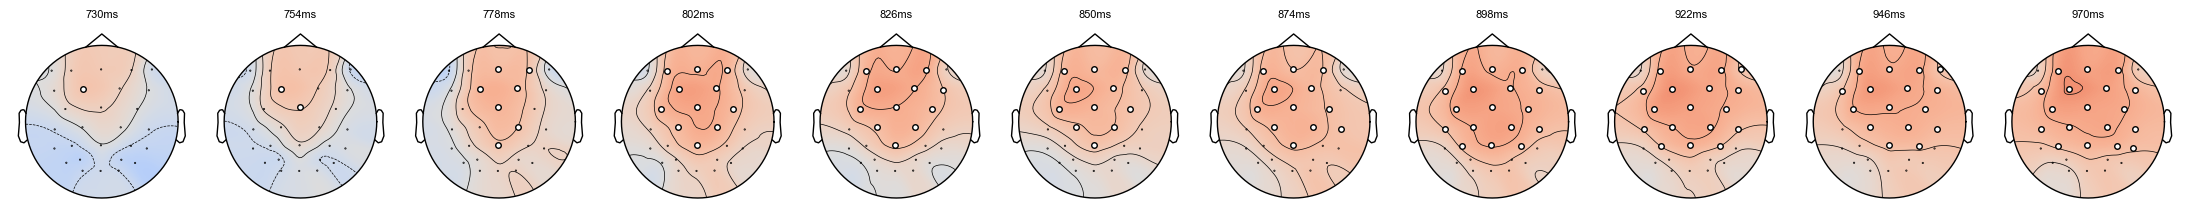

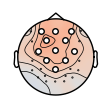

Significant spatio-temporal cluster found with p-value 0.0001


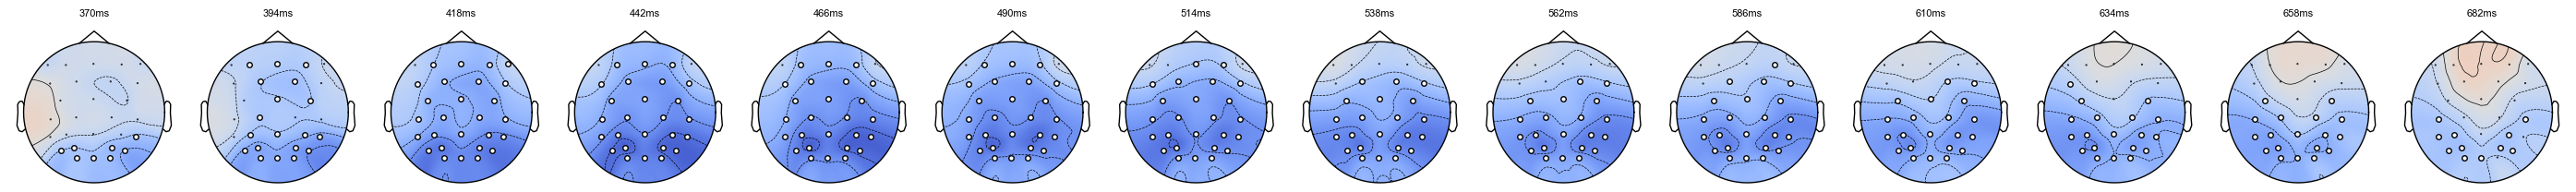

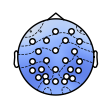

In [21]:
all_clusters_info = []
for c, p_val in zip(clusters, cluster_p_values):
    if p_val < 0.05:
        print(f"Significant spatio-temporal cluster found with p-value {p_val:.4f}")
        time_idxs, chan_idxs = c
        curr_times = np.unique(time_idxs)
        fig, axes = plt.subplots(1, len(curr_times), figsize=(2 * len(curr_times), 4))

        # curr_mask = np.zeros(haufes_reordered.shape[0], dtype=bool)
        # curr_mask[chan_idxs] = True
        for it, t in enumerate(curr_times):
            curr_chans = chan_idxs[time_idxs == t]
            curr_mask = np.zeros(28, dtype=bool)
            curr_mask[curr_chans] = True

            im, _ = mne.viz.plot_topomap(
                haufes_reordered[:, t, :].mean(0),
                info,
                axes=axes[it],
                show=False,
                contours=4,
                vlim=(-0.3, 0.3),
                cmap="coolwarm",
                mask=curr_mask,
                mask_params=dict(marker="o", markerfacecolor="w", markersize=4),
            )
            axes[it].set_title(f"{times[t]}ms", fontsize=8)
        # plt.suptitle(f"{times[curr_times[0]]} - {times[curr_times[-1]]} ms, p={p_val:.4f}", fontsize=12)
        plt.savefig(
            f"figures/decoding_desc-{RUN_DESCRIPTION}_HaufeTopomap_cluster_{times[curr_times[0]]}_{times[curr_times[-1]]}ms.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.tight_layout()
        plt.show()
        plt.close()
        # get the median time of the cluster. If there are an even number of time points, take the average of the two middle time points
        median_time = np.median(curr_times)
        if len(curr_times) % 2 == 0:
            median_times = np.array([median_time - 0.5, median_time + 0.5])
        else:
            median_times = np.array([median_time])
        # plot the topomap that is the average of the mean haufe values across the median time points of the cluster
        median_diff = haufes_reordered[:, median_times.astype(int), :].mean(1).mean(0)
        median_chans = chan_idxs[np.isin(time_idxs, median_times)]
        median_mask = np.zeros(28, dtype=bool)
        median_mask[median_chans] = True
        im, _ = mne.viz.plot_topomap(
            median_diff,
            info,
            show=False,
            contours=4,
            vlim=(-0.3, 0.3),
            cmap="coolwarm",
            mask=median_mask,
            mask_params=dict(marker="o", markerfacecolor="w", markersize=4),
        )
        plt.savefig(
            f"figures/decoding_desc-{RUN_DESCRIPTION}_HaufeTopomap_clusterMEDIAN_{times[int(median_times[0])]}_{times[int(median_times[-1])]}ms.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()
        plt.close()
        all_clusters_info.append(
            {
                "p_value": p_val,
                "time_idxs": time_idxs,
                "chan_idxs": chan_idxs,
                "median_time": median_time,
                "median_chans": median_chans,
            }
        )

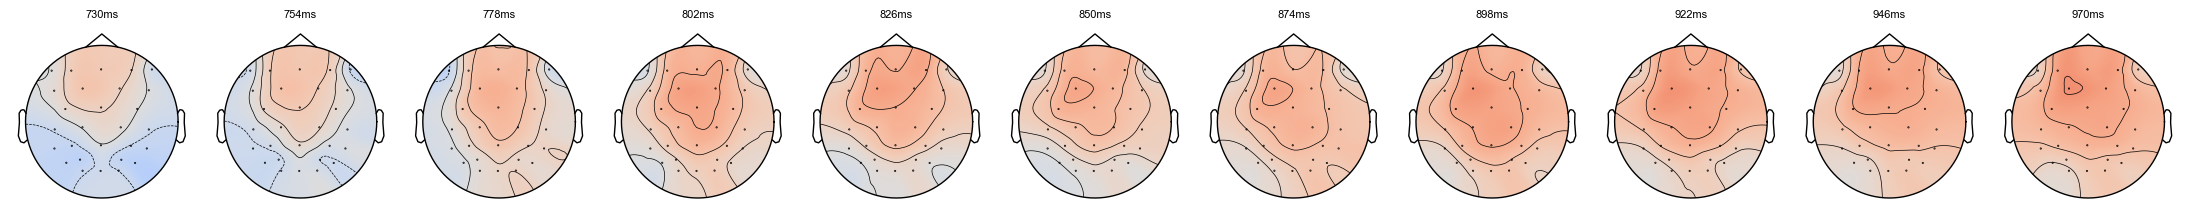

In [22]:
# Examine the TOPO during the later WM cluster to see if it's consistent across tasks

late_WM_cluster_tidx = np.arange(44, 55)


fig, axes = plt.subplots(1, len(late_WM_cluster_tidx), figsize=(2 * len(late_WM_cluster_tidx), 4))

# curr_mask = np.zeros(haufes_reordered.shape[0], dtype=bool)
# curr_mask[chan_idxs] = True
for it, t in enumerate(late_WM_cluster_tidx):
    curr_mask = np.zeros(28, dtype=bool)  # all False

    im, _ = mne.viz.plot_topomap(
        haufes_reordered[:, t, :].mean(0),
        info,
        axes=axes[it],
        show=False,
        contours=4,
        vlim=(-0.3, 0.3),
        cmap="coolwarm",
        mask=curr_mask,
        mask_params=dict(marker="o", markerfacecolor="w", markersize=4),
    )
    axes[it].set_title(f"{times[t]}ms", fontsize=8)

plt.tight_layout()
plt.show()
plt.close()

### Plot just the test results for the 2 training conditions

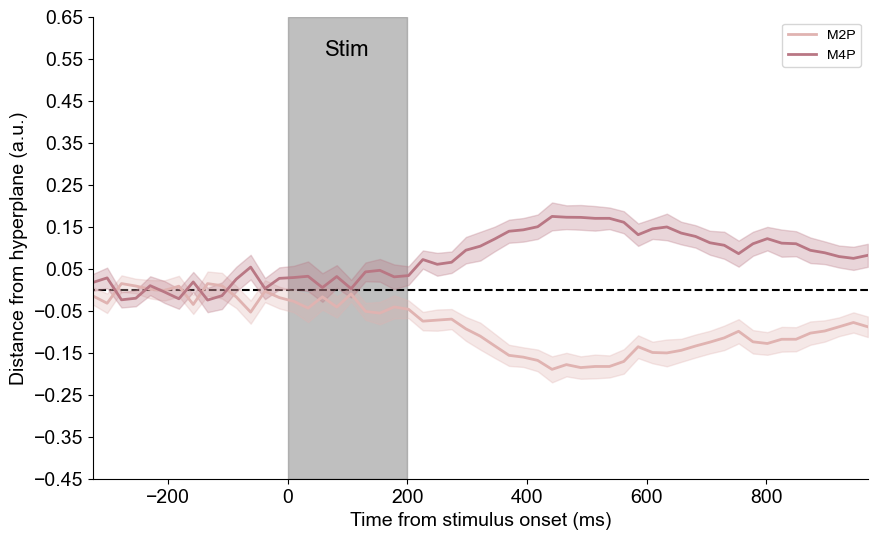

In [23]:
plot_training_conds(preds_mean, preds_lower, preds_upper, times, training_labels, suffix=None)

## Looking at all of the conditions in the same task

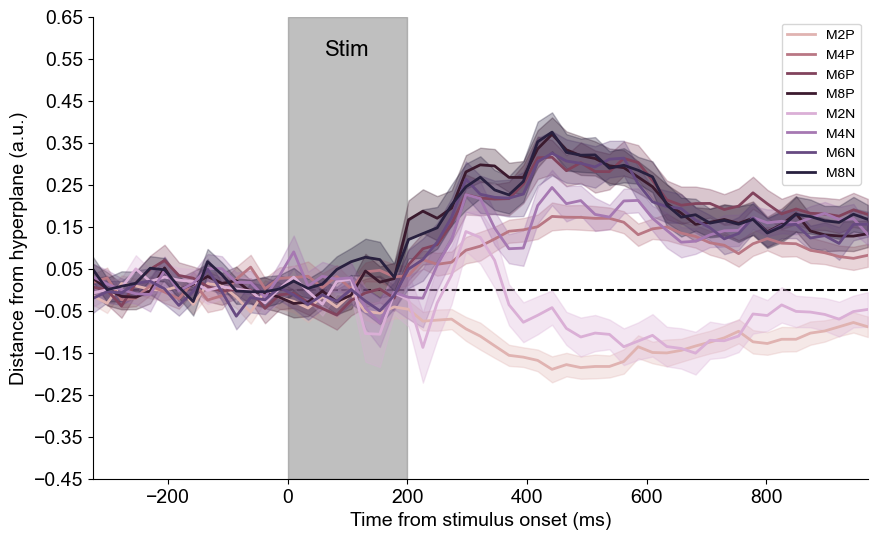

In [24]:
plot_task_conds(preds_mean, preds_lower, preds_upper, times, suffix=None)

# Looking at the training conditions + the conditions of the other task

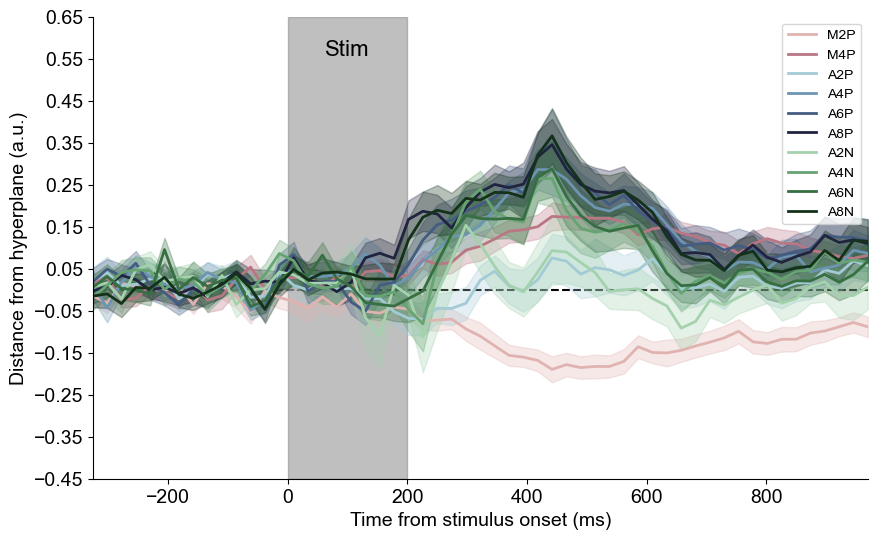

In [25]:
plot_alt_conds(preds_mean, preds_lower, preds_upper, times, suffix=None)

## All conditions, with SEM only on training conds

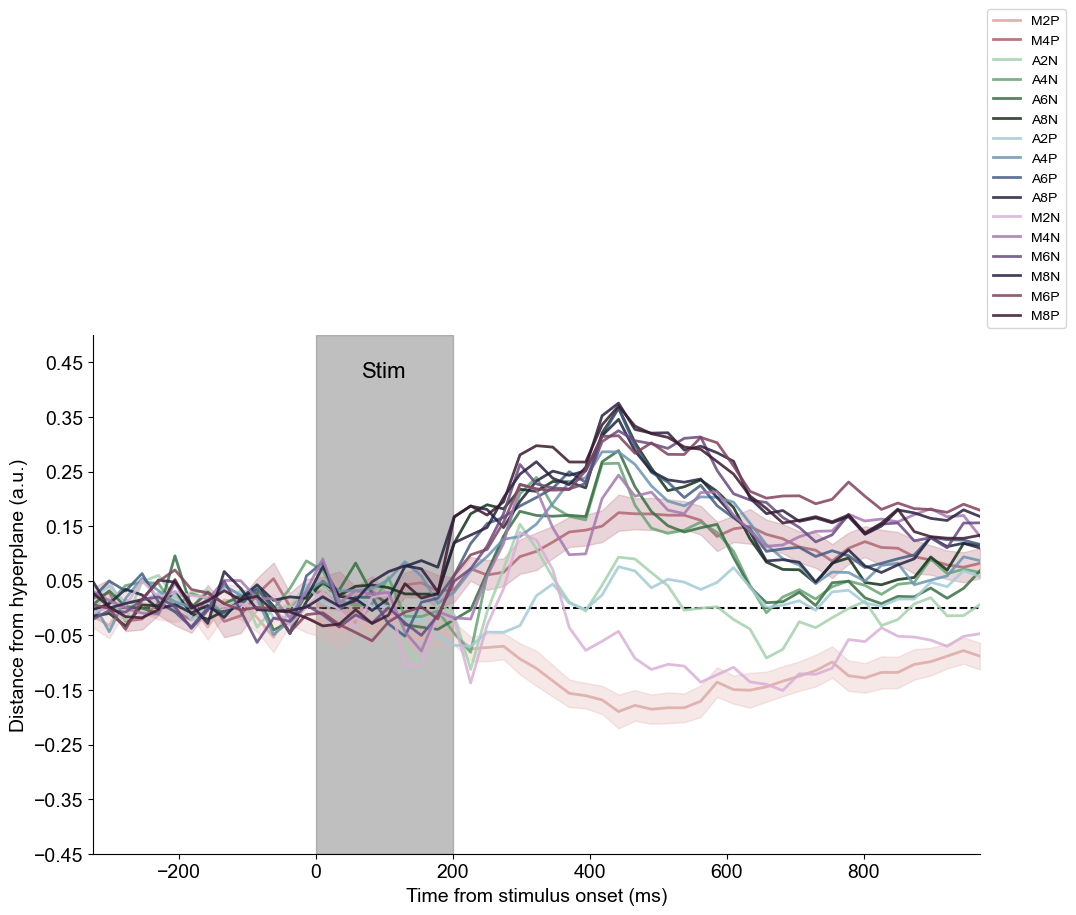

In [26]:
plot_all_conds(preds_mean, preds_lower, preds_upper, times, suffix=None)

# Plot the Hyperplane Contrast for the 4 conditions: 4-2 A/M, N/P

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/mne/stats/parametric.py:60: RuntimeWarning: invalid value encountered in divide
  return np.mean(X, axis=0) / np.sqrt(var / X.shape[0])


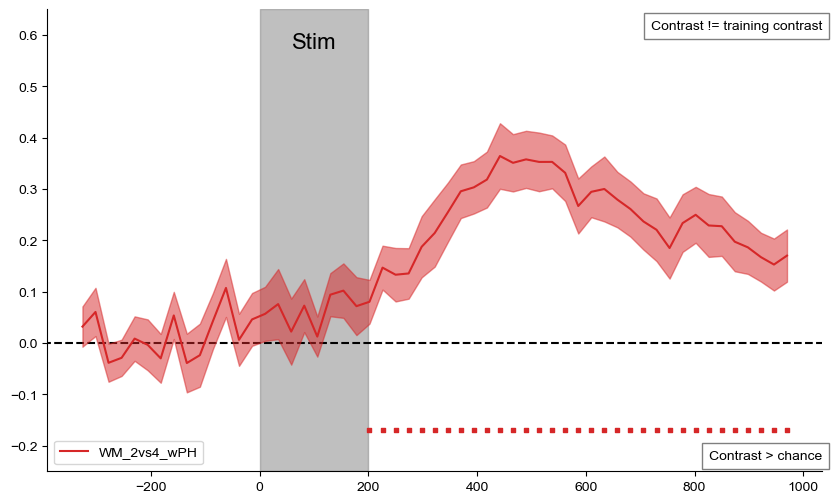

In [27]:
plot_contrasts(preds_per_sub, times, suffix="noGen", generalize=False)

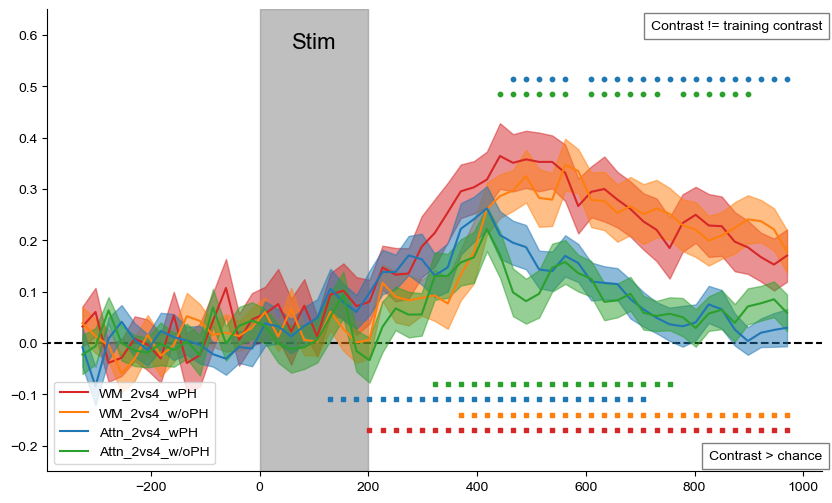

In [28]:
plot_contrasts(preds_per_sub, times, suffix=None)

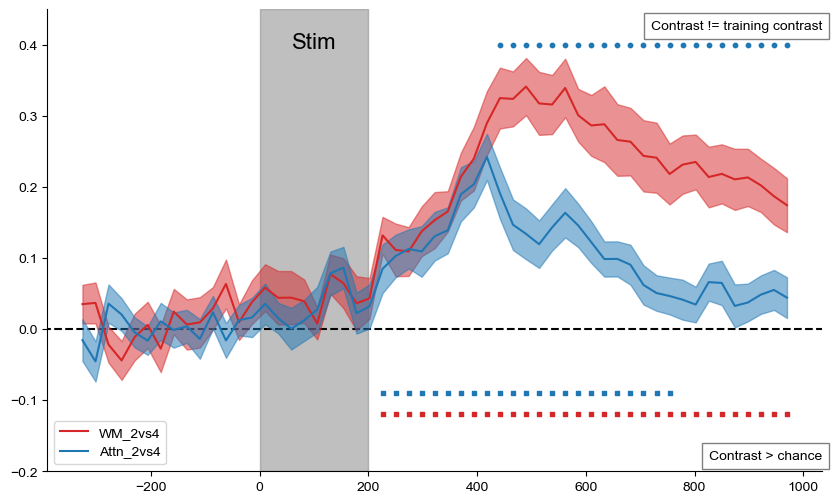

In [29]:
plot_contrasts_averagePH(preds_per_sub, times)

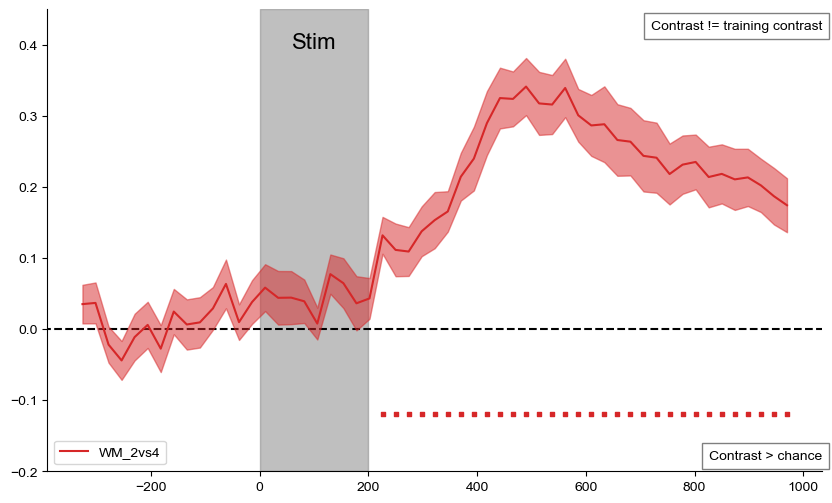

In [30]:
plot_contrasts_averagePH(preds_per_sub, times, generalize=False, suffix="noGen")

## Looking at the delay average and whether there are any task effects or interactions
### NOTE: only including the delay period when attentnional probes could be presented (300ms-1100ms)

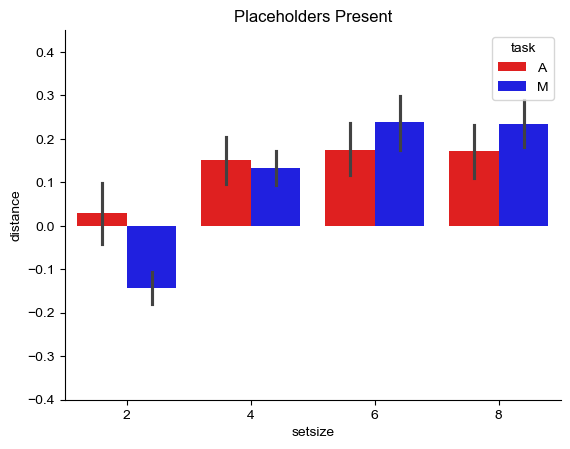

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,setsize,2.387534,3,75,0.795845,48.613853,1.473382e-17,1.740216e-13,0.356263,0.734022
1,task,0.014871,1,25,0.014871,0.403219,5.312005e-01,5.312005e-01,0.003435,1.000000
2,setsize * task,0.473577,3,75,0.157859,14.318682,1.816579e-07,2.278090e-06,0.098916,0.798871


only SSs 2 and 4, since those are the training conditions for the contrasts


/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,setsize,1.018358,1,25,1.018358,62.888331,2.755675e-08,2.755675e-08,0.347551,1.0
1,task,0.237227,1,25,0.237227,10.894378,2.900461e-03,2.900461e-03,0.110391,1.0
2,setsize * task,0.152221,1,25,0.152221,10.830518,2.970728e-03,2.970728e-03,0.073752,1.0


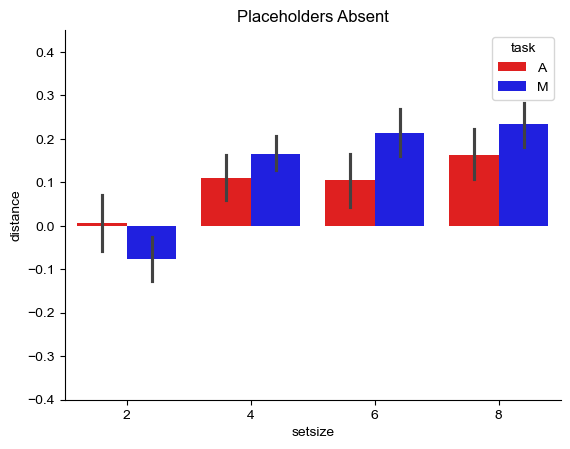

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,setsize,1.646586,3,75,0.548862,33.372605,8.249775e-14,1.220140e-09,0.280078,0.641556
1,task,0.075961,1,25,0.075961,2.437626,1.310264e-01,1.310264e-01,0.017631,1.000000
2,setsize * task,0.274601,3,75,0.091534,10.244244,9.898859e-06,4.936559e-05,0.060927,0.817090


In [31]:
plot_bar_plots_ANOVAs(preds_per_sub)

# Looking at Eye & Pupil Predictions!

In [32]:
from statsmodels.stats.multitest import multipletests

In [33]:
def plot_haufe_eyes(haufe_eyes, current_chan_names, suffix):
    eye_feature_clusters = {}
    min_p_values = []
    # for each of the 12 eye features. we will get the cluster-based permutation test results and save out the clusters
    for i in range(haufe_eyes.shape[1]):
        _, feat_clusters, feat_cluster_p_values, _ = spatio_temporal_cluster_1samp_test(
            haufe_eyes[:, i, :], n_permutations=10000, adjacency=None, tail=0
        )
        if len(feat_clusters) > 0:
            print(
                f"Significant spatio-temporal cluster found for eye feature {i} with p-value {feat_cluster_p_values.min():.4f}"
            )
            min_p_values.append(feat_cluster_p_values.min())
            eye_feature_clusters[i] = {
                "clusters": feat_clusters,
                "cluster_p_values": feat_cluster_p_values,
            }
        else:
            eye_feature_clusters[i] = {
                "clusters": [],
                "cluster_p_values": [],
            }

    multitest_results = multipletests(min_p_values, alpha=0.05, method="fdr_bh")
    sig_bool = multitest_results[0]
    sig_pvals = np.array(min_p_values)[sig_bool]
    if len(sig_pvals) > 0:
        print(f"Significant eye features after FDR correction: {np.where(sig_bool)[0]} with p-values {sig_pvals}")
        # use the highest significant p-value as the threshold for plotting
        pval_threshold = sig_pvals.max()
    else:
        print("No significant eye features after FDR correction.")
        pval_threshold = 0  # this will ensure that no clusters are plotted

    # make a figure with a line for each eye feature and a cluster threshold if past significance threshold
    fig, axes = plt.subplots(nrows=haufe_eyes.shape[1], ncols=1, figsize=(6, 1.25 * haufe_eyes.shape[1]), sharex=True)

    for i in eye_feature_clusters.keys():
        curr_haufe = haufe_eyes[:, i, :]
        # pivot into a long format for seaborn plotting
        wide_haufe_df = pd.DataFrame(curr_haufe, columns=times)
        wide_haufe_df["subid"] = np.arange(curr_haufe.shape[0])
        melted_haufe = wide_haufe_df.melt(var_name="time", value_name=current_chan_names[i], id_vars="subid")

        sns.lineplot(x="time", y=current_chan_names[i], data=melted_haufe, ax=axes[i])
        axes[i].axhline(0, color="black", linestyle="--", alpha=1, zorder=-1, xmin=times.min(), xmax=times.max())

        clusters = eye_feature_clusters[i]["clusters"]
        cluster_p_values = eye_feature_clusters[i]["cluster_p_values"]
        sig_clusters = [c for c, p in zip(clusters, cluster_p_values) if p <= pval_threshold]
        if len(sig_clusters) > 0:
            for c in sig_clusters:
                c_start = times[c[0].min()]
                c_end = times[c[0].max()]
                print(f"Plotting significant cluster for eye feature {i} from {c_start} to {c_end} ms")
                axes[i].axvspan(c_start, c_end, color="red", alpha=0.3)
        axes[i].set_ylabel(current_chan_names[i], fontsize=8)
        sns.despine()

    plt.savefig(
        f"figures/decoding_desc-{RUN_DESCRIPTION}_HaufeEyes-{suffix}.png",
        dpi=300,
        bbox_inches="tight",
        transparent=True,
    )
    plt.show()
    plt.close()

In [34]:
eye_feature_name_map = {
    "pupil_left": "Left Pupil",
    "pupil_right": "Right Pupil",
    "pupil_left_TD": "Left Pupil (TD)",
    "pupil_right_TD": "Right Pupil (TD)",
    "xpos_left": "Left X Position",
    "xpos_right": "Right X Position",
    "ypos_left": "Left Y Position",
    "ypos_right": "Right Y Position",
    "dist_left": "Left Distance",
    "dist_right": "Right Distance",
    "xpos_left_TD": "Left X Position (TD)",
    "xpos_right_TD": "Right X Position (TD)",
    "ypos_left_TD": "Left Y Position (TD)",
    "ypos_right_TD": "Right Y Position (TD)",
    "dist_left_TD": "Left Distance (TD)",
    "dist_right_TD": "Right Distance (TD)",
}

In [35]:
def eye_pipeline(SUFFIX):
    assert SUFFIX in ["EYES", "PUPIL"], "SUFFIX must be either 'EYES' or 'PUPIL'"

    preds_all_eyes, haufe_eyes, times = interp.dataset.get_data(
        None, keys=[f"preds{SUFFIX}", f"Haufe{SUFFIX}", "times"]
    )

    preds_per_sub_eyes = preds_all_eyes.mean(2).mean(
        1
    )  # flatten across folds and then reps (I know order doesn't matter, but like the concepual clarity)

    preds_mean_eyes, preds_upper_eyes, preds_lower_eyes = interp.get_plot_line(
        preds_per_sub_eyes
    )  # get the mean and upper/lower SEM bounds, for pretty plotting

    haufe_eyes = haufe_eyes.mean(2).mean(1)

    curr_chan_idx = pupil_chan_idx if SUFFIX == "PUPIL" else eyeOnly_chan_idx
    current_chan_names = np.array(eye_chan_names)[curr_chan_idx]
    nice_chan_names = [eye_feature_name_map.get(ch, ch) for ch in current_chan_names]

    plot_haufe_eyes(haufe_eyes, nice_chan_names, SUFFIX)

    plot_training_conds(preds_mean_eyes, preds_lower_eyes, preds_upper_eyes, times, training_labels, suffix=SUFFIX)
    plot_task_conds(preds_mean_eyes, preds_lower_eyes, preds_upper_eyes, times, suffix=SUFFIX)
    plot_alt_conds(preds_mean_eyes, preds_lower_eyes, preds_upper_eyes, times, suffix=SUFFIX)
    plot_all_conds(preds_mean_eyes, preds_lower_eyes, preds_upper_eyes, times, suffix=SUFFIX)
    plot_contrasts(preds_per_sub_eyes, times, suffix=f"{SUFFIX}noGen", generalize=False)
    plot_contrasts(preds_per_sub_eyes, times, suffix=SUFFIX)
    plot_contrasts_averagePH(preds_per_sub_eyes, times, suffix=SUFFIX)
    plot_contrasts_averagePH(preds_per_sub_eyes, times, generalize=False, suffix=f"{SUFFIX}noGen")

Significant spatio-temporal cluster found for eye feature 0 with p-value 0.1266
Significant spatio-temporal cluster found for eye feature 1 with p-value 0.1092
Significant spatio-temporal cluster found for eye feature 2 with p-value 0.0048
Significant spatio-temporal cluster found for eye feature 3 with p-value 0.0007
Significant eye features after FDR correction: [2 3] with p-values [0.0048 0.0007]
Plotting significant cluster for eye feature 2 from 754 to 970 ms
Plotting significant cluster for eye feature 3 from 682 to 970 ms


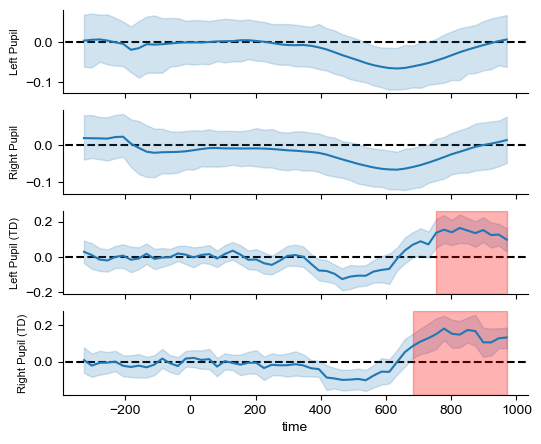

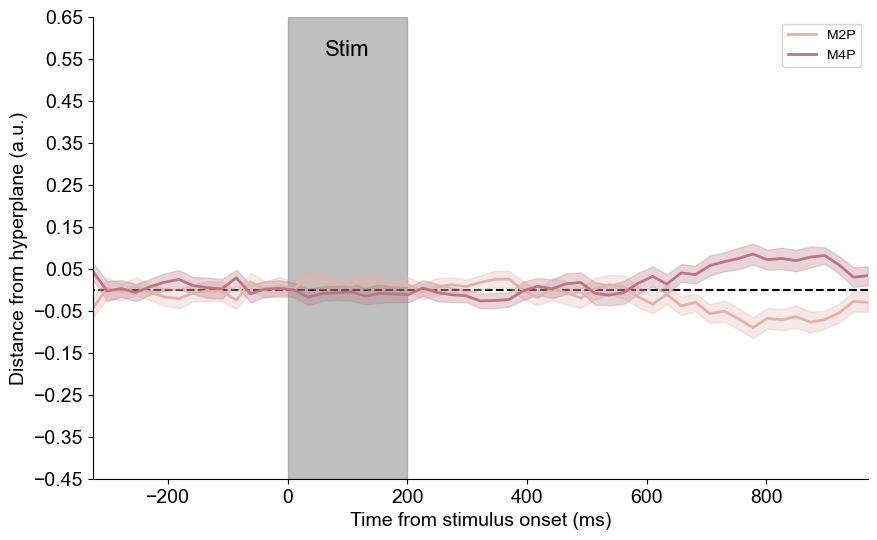

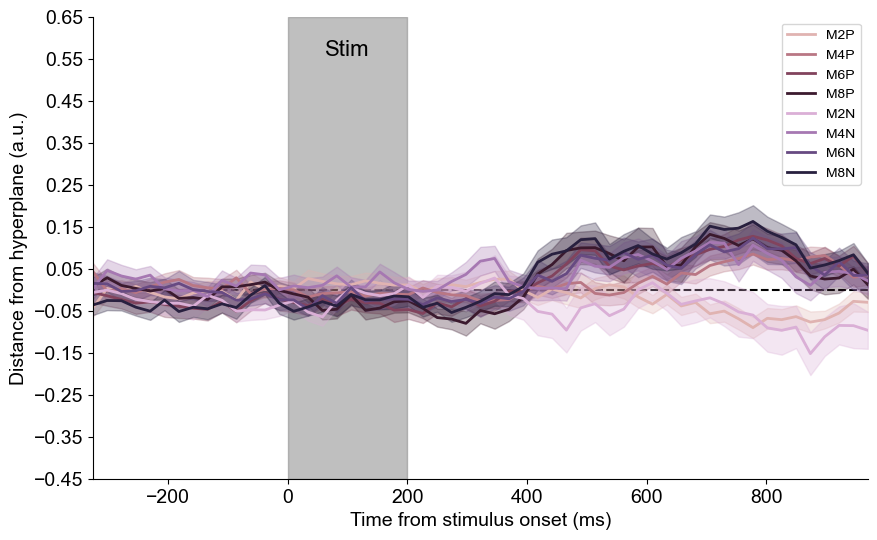

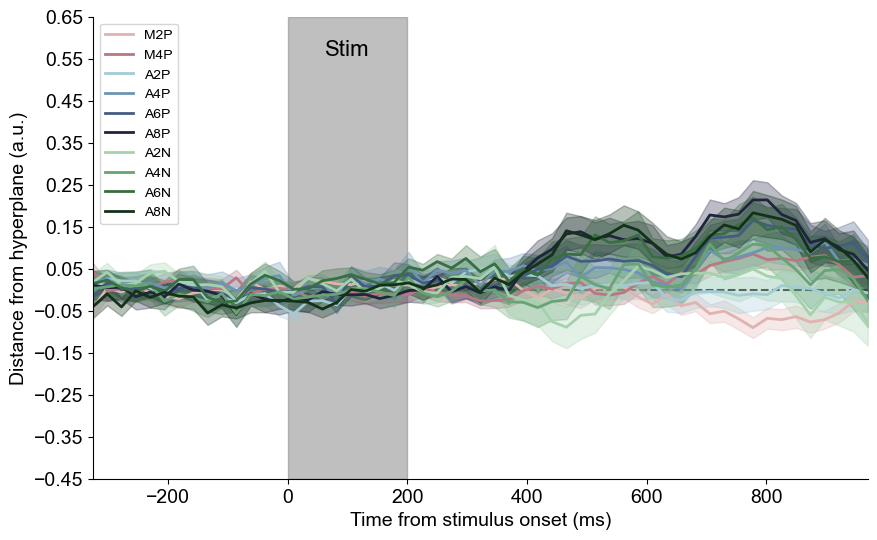

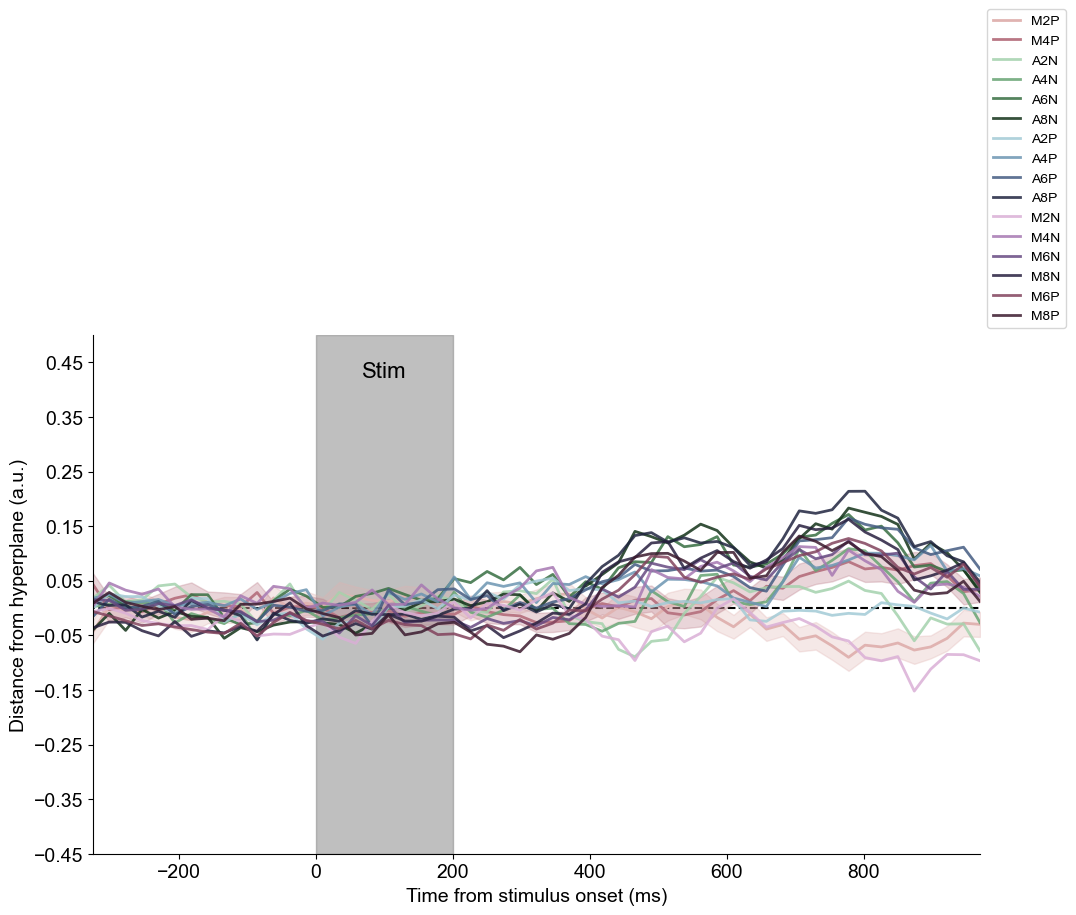

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/mne/stats/parametric.py:60: RuntimeWarning: invalid value encountered in divide
  return np.mean(X, axis=0) / np.sqrt(var / X.shape[0])


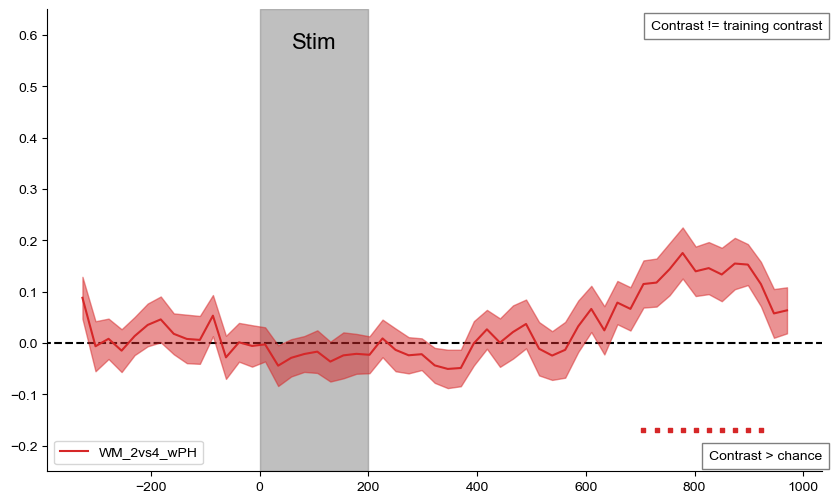

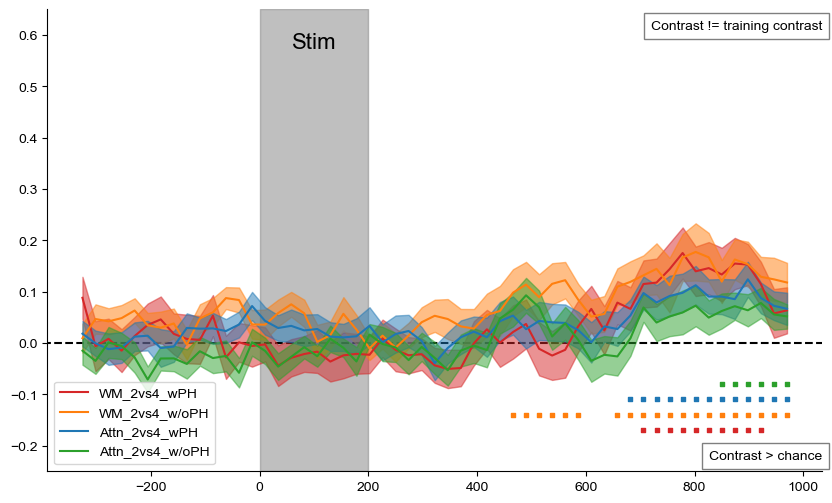

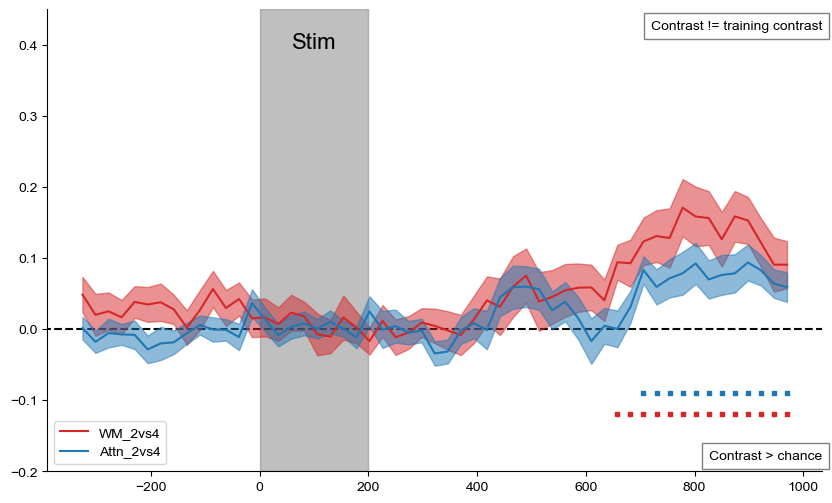

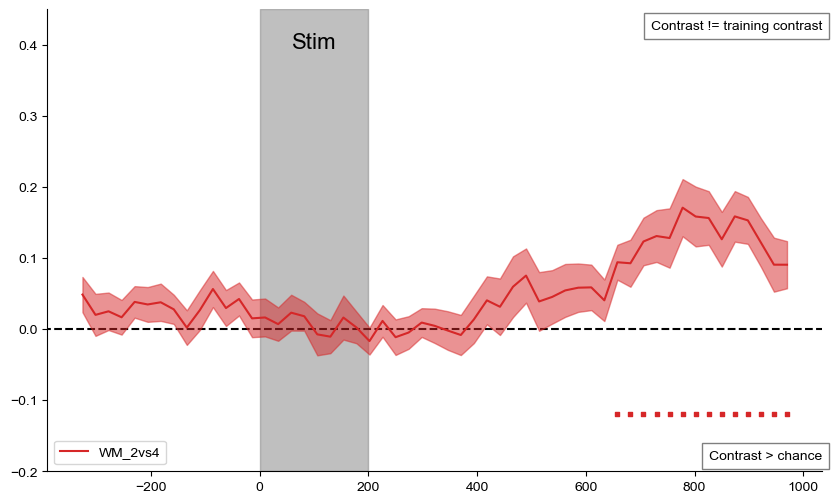

In [36]:
eye_pipeline("PUPIL")

Significant spatio-temporal cluster found for eye feature 1 with p-value 0.0907
Significant spatio-temporal cluster found for eye feature 5 with p-value 0.3101
Significant spatio-temporal cluster found for eye feature 6 with p-value 0.3868
Significant spatio-temporal cluster found for eye feature 7 with p-value 0.0746
Significant spatio-temporal cluster found for eye feature 8 with p-value 0.7928
Significant spatio-temporal cluster found for eye feature 9 with p-value 0.1334
Significant spatio-temporal cluster found for eye feature 10 with p-value 0.6424
Significant spatio-temporal cluster found for eye feature 11 with p-value 0.5496
No significant eye features after FDR correction.


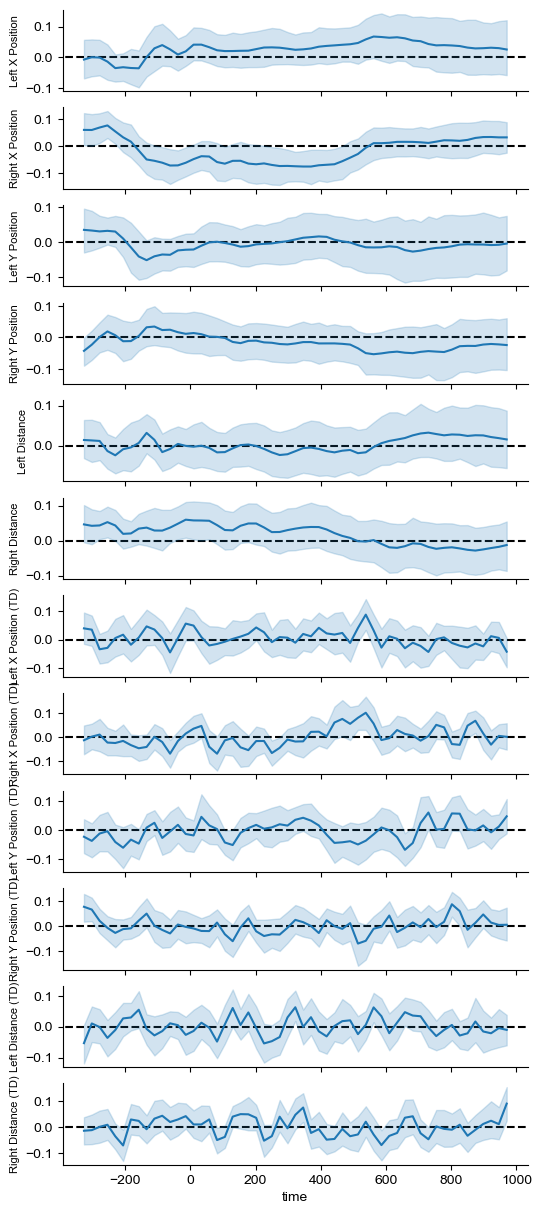

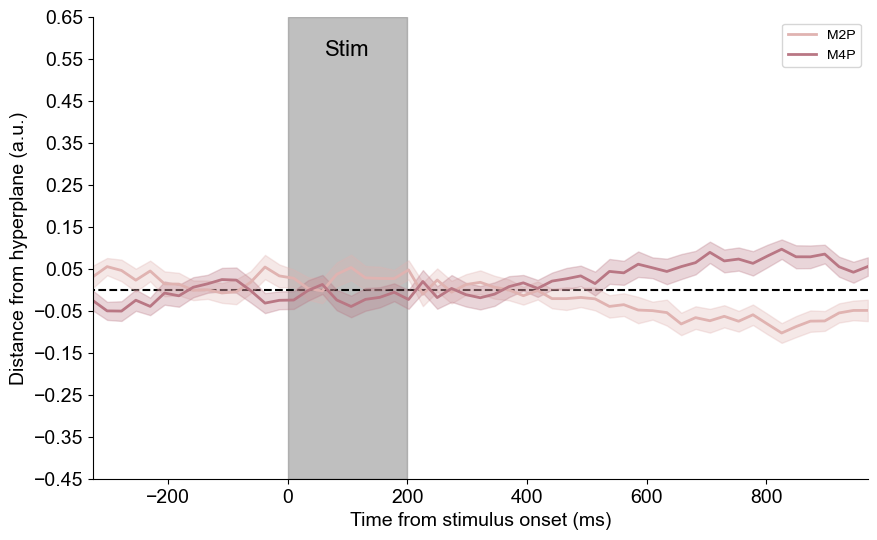

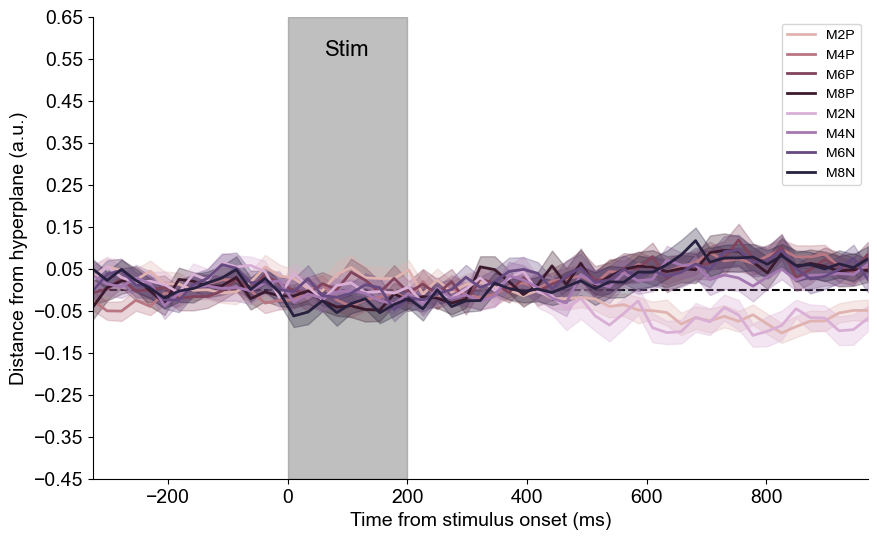

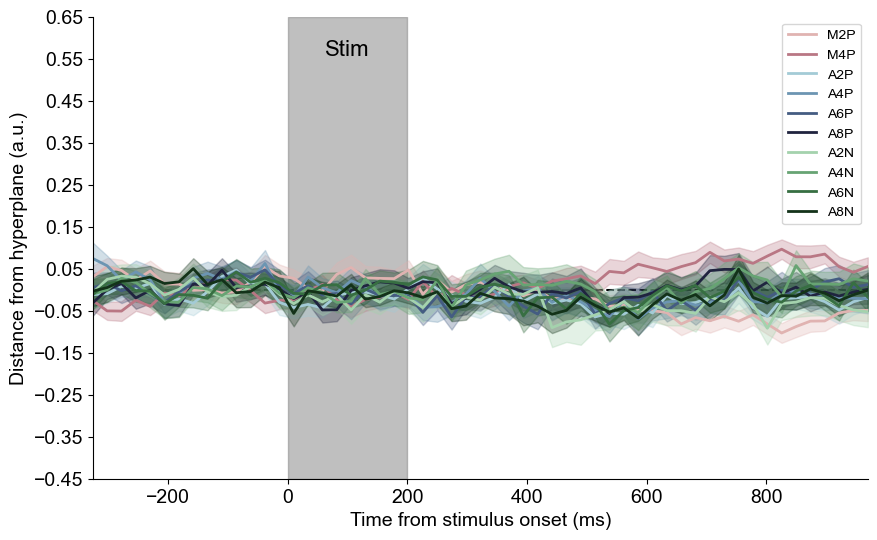

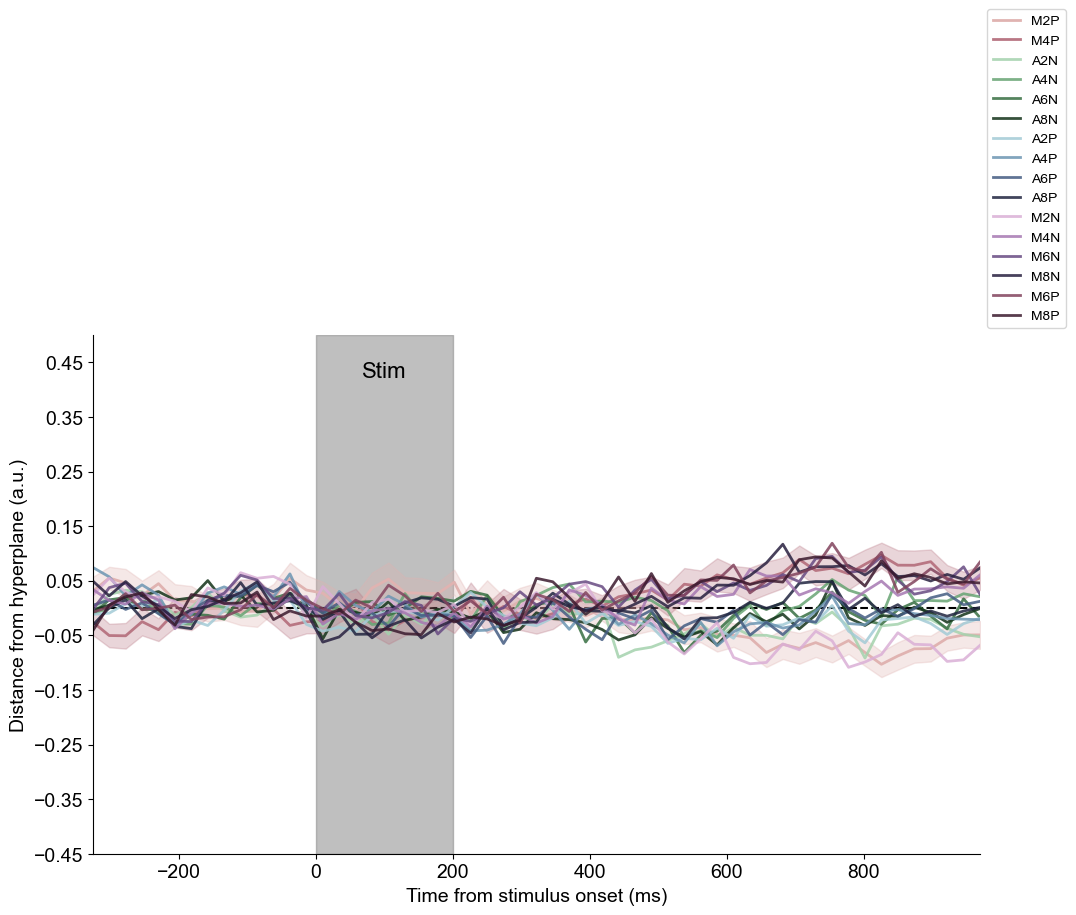

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/mne/stats/parametric.py:60: RuntimeWarning: invalid value encountered in divide
  return np.mean(X, axis=0) / np.sqrt(var / X.shape[0])


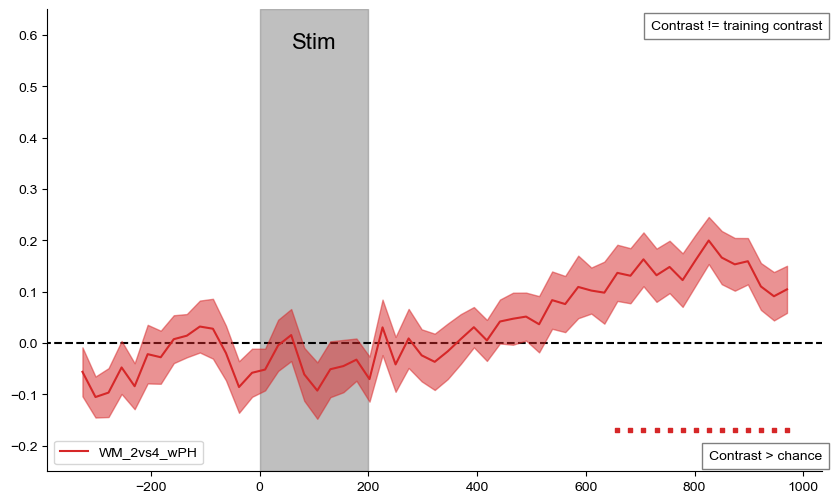

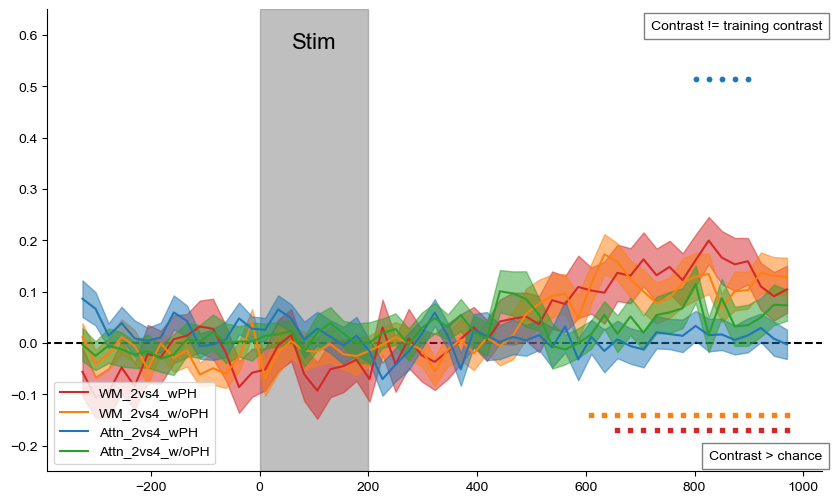

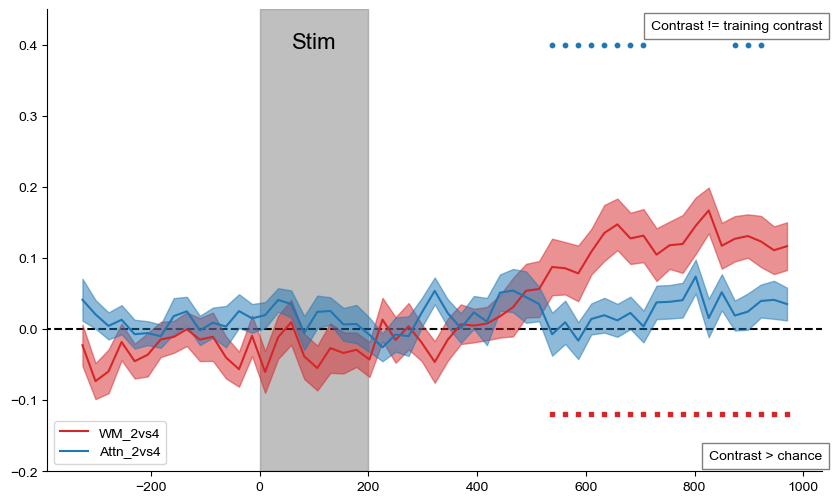

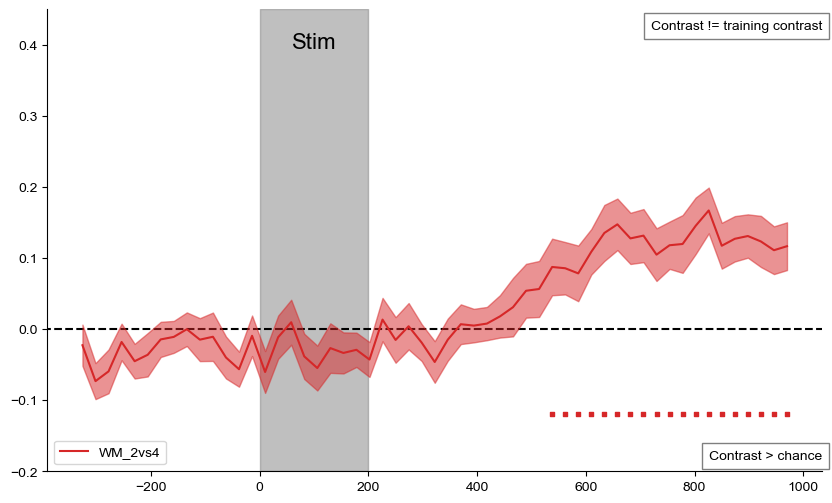

In [37]:
eye_pipeline("EYES")

# Look at the predictions based on what the model was trained on, attention or WM

In [38]:
attn_interp = mvEEG.Interpreter(
    data_dir=ROOT,
    experiment_name=EXPERIMENT_NAME,
    descriptions=["A2PvsA4P"],
    labels=[0, 1],
    trial_phases={"Stim": (0, 200)},
    key_set=["times", "preds", "Haufe", "weights"],
)
preds_attn, times, haufe_attn, weights_attn = attn_interp.dataset.get_data(
    None, keys=["preds", "times", "Haufe", "weights"]
)
preds_attn_per_sub = preds_attn.mean(2).mean(1)[:, delay_window, :].mean(1)
full_df_attn = pd.DataFrame(preds_attn_per_sub, columns=conditions)
full_df_attn["subject"] = full_df_attn.index.values
melted_df_attn = full_df_attn.melt(id_vars="subject", var_name="condition", value_name="distance")
melted_df_attn.loc[:, "task"] = melted_df_attn.condition.str[0]
melted_df_attn.loc[:, "setsize"] = melted_df_attn.condition.str[1]
melted_df_attn["training_conditions"] = "Attention"
melted_df_attn["placeholder"] = melted_df_attn.condition.str[2] == "P"

del attn_interp

wm_interp = mvEEG.Interpreter(
    data_dir=ROOT,
    experiment_name=EXPERIMENT_NAME,
    descriptions=["M2PvsM4P"],
    labels=[0, 1],
    trial_phases={"Stim": (0, 200)},
    key_set=["preds", "Haufe", "weights"],
)
preds_wm, haufe_wm, weights_wm = wm_interp.dataset.get_data(None, keys=["preds", "Haufe", "weights"])
preds_wm_per_sub = preds_wm.mean(2).mean(1)[:, delay_window, :].mean(1)
full_df_wm = pd.DataFrame(preds_wm_per_sub, columns=conditions)
full_df_wm["subject"] = full_df_wm.index.values
melted_df_wm = full_df_wm.melt(id_vars="subject", var_name="condition", value_name="distance")
melted_df_wm.loc[:, "task"] = melted_df_wm.condition.str[0]
melted_df_wm.loc[:, "setsize"] = melted_df_wm.condition.str[1]
melted_df_wm["training_conditions"] = "Working Memory"
melted_df_wm["placeholder"] = melted_df_wm.condition.str[2] == "P"

combined_df = pd.concat([melted_df_attn, melted_df_wm], axis=0).reset_index(drop=True)

del wm_interp

# Difference in Haufe between WM and Attention (WM - Attention)

In [39]:
haufe_task_diff = haufe_wm.mean(2).mean(1) - haufe_attn.mean(2).mean(1)

haufe_task_diff_reordered = np.moveaxis(haufe_task_diff, 2, 1)

t_obs, clusters, cluster_p_values, _ = spatio_temporal_cluster_1samp_test(
    haufe_task_diff_reordered, n_permutations=10000, adjacency=adjacency, tail=0
)

Significant spatio-temporal cluster found with p-value 0.0077


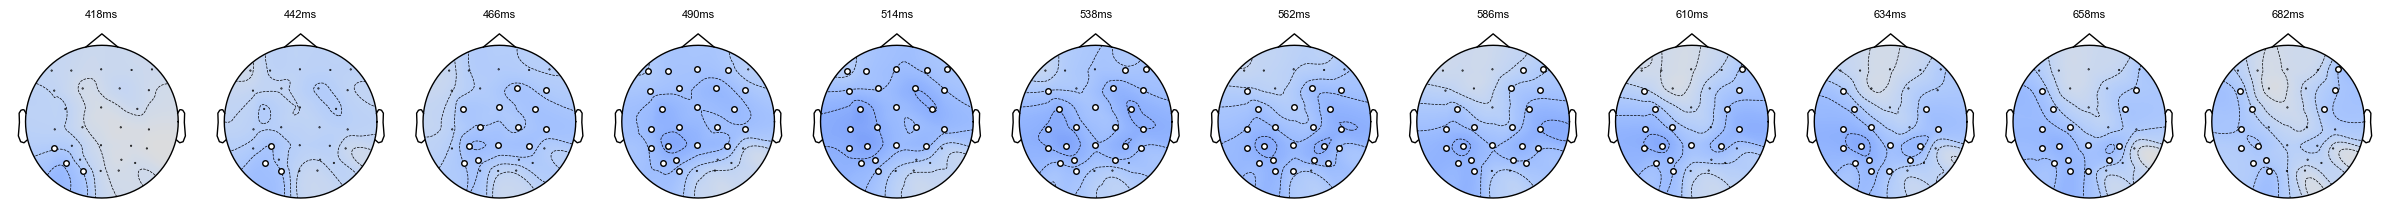

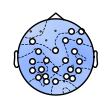

In [40]:
all_diff_clusters_info = []
for c, p_val in zip(clusters, cluster_p_values):
    if p_val < 0.05:
        print(f"Significant spatio-temporal cluster found with p-value {p_val:.4f}")
        time_idxs, chan_idxs = c
        curr_times = np.unique(time_idxs)
        fig, axes = plt.subplots(1, len(curr_times), figsize=(2 * len(curr_times), 4))

        curr_mask[chan_idxs] = True
        for it, t in enumerate(curr_times):
            curr_chans = chan_idxs[time_idxs == t]
            curr_mask = np.zeros(28, dtype=bool)
            curr_mask[curr_chans] = True

            im, _ = mne.viz.plot_topomap(
                haufe_task_diff_reordered[:, t, :].mean(0),
                info,
                axes=axes[it],
                show=False,
                contours=4,
                vlim=(-0.3, 0.3),
                cmap="coolwarm",
                mask=curr_mask,
                mask_params=dict(marker="o", markerfacecolor="w", markersize=4),
            )
            axes[it].set_title(f"{times[t]}ms", fontsize=8)
        plt.tight_layout()
        plt.savefig(
            f"figures/decoding_desc_HaufeTopomap_taskDiff_cluster_{times[curr_times[0]]}_{times[curr_times[-1]]}ms.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()
        plt.close()
        # get the median time of the cluster. If there are an even number of time points, take the average of the two middle time points
        median_time = np.median(curr_times)
        if len(curr_times) % 2 == 0:
            median_times = np.array([median_time - 0.5, median_time + 0.5])
        else:
            median_times = np.array([median_time])
        # plot the topomap that is the average of the mean importances across the median time points of the cluster
        median_diff = haufe_task_diff_reordered[:, median_times.astype(int), :].mean(1).mean(0)
        median_chans = chan_idxs[np.isin(time_idxs, median_times)]
        median_mask = np.zeros(28, dtype=bool)
        median_mask[median_chans] = True
        im, _ = mne.viz.plot_topomap(
            median_diff,
            info,
            show=False,
            contours=4,
            vlim=(-0.3, 0.3),
            cmap="coolwarm",
            mask=median_mask,
            mask_params=dict(marker="o", markerfacecolor="w", markersize=4),
        )
        plt.savefig(
            f"figures/decoding_desc_HaufeTopomap_taskDiff_clusterMEDIAN_{times[int(median_times[0])]}_{times[int(median_times[-1])]}ms.png",
            dpi=300,
            transparent=True,
            bbox_inches="tight",
        )
        plt.show()
        plt.close()
        all_diff_clusters_info.append(
            {
                "p_value": p_val,
                "time_idxs": time_idxs,
                "chan_idxs": chan_idxs,
                "median_time": median_time,
                "median_chans": median_chans,
            }
        )
        # plt.colorbar(im, fraction=0.01, pad=0.04).set_label("Haufe Importance Difference (WM - Attn)", fontsize=12)

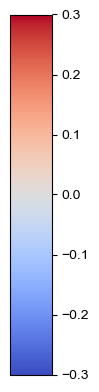

In [41]:
fig = plt.figure(figsize=(1.2, 4))
cax = fig.add_axes([0.05, 0.05, 0.35, 0.9])  # left, bottom, width, height
norm = plt.Normalize(vmin=-0.3, vmax=0.3)
sm = plt.cm.ScalarMappable(cmap="coolwarm", norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax, orientation="vertical")
# cbar.set_label("Haufe Importance Difference (WM - Attn)", fontsize=12)
plt.savefig("figures/decoding_desc-Haufe_colorbar.svg", bbox_inches="tight", transparent=True)
plt.show()
plt.close()

# Difference in Weights between WM and Attention
### If they differ across extra times compared to above, it could be due to systematic differences in noise

In [42]:
weights_task_diff = weights_wm.mean(2).mean(1) - weights_attn.mean(2).mean(1)

weights_task_diff_reordered = np.moveaxis(weights_task_diff, 2, 1)

t_obs, clusters, cluster_p_values, _ = spatio_temporal_cluster_1samp_test(
    weights_task_diff_reordered, n_permutations=10000, adjacency=adjacency, tail=0
)
cluster_p_values

array([1.    , 1.    , 1.    , 1.    , 1.    , 1.    , 0.999 , 1.    ,
       1.    , 1.    , 1.    , 1.    , 1.    , 1.    , 1.    , 1.    ,
       0.9996, 1.    , 0.3202, 1.    , 1.    , 1.    , 1.    , 1.    ,
       1.    , 1.    , 1.    , 1.    , 0.9848, 0.9959, 1.    , 0.9994,
       1.    , 1.    , 0.9985, 1.    , 1.    , 1.    , 0.9923, 0.9992,
       1.    , 1.    , 1.    , 1.    ])

In [43]:
for c, p_val in zip(clusters, cluster_p_values):
    if p_val < 0.05:
        print(f"Significant spatio-temporal cluster found with p-value {p_val:.4f}")
        time_idxs, chan_idxs = c
        curr_times = np.unique(time_idxs)
        fig, axes = plt.subplots(1, len(curr_times), figsize=(2 * len(curr_times), 4))

        curr_mask[chan_idxs] = True
        for it, t in enumerate(curr_times):
            curr_chans = chan_idxs[time_idxs == t]
            curr_mask = np.zeros(28, dtype=bool)
            curr_mask[curr_chans] = True

            im, _ = mne.viz.plot_topomap(
                weights_task_diff_reordered[:, t, :].mean(0),
                info,
                axes=axes[it],
                show=False,
                contours=4,
                # vlim=(-0.3, 0.3),
                cmap="coolwarm",
                mask=curr_mask,
                mask_params=dict(marker="o", markerfacecolor="w", markersize=4),
            )
            axes[it].set_title(f"{times[t]}ms", fontsize=8)
        plt.tight_layout()
        # plt.savefig(
        #     f"figures/decoding_desc_HaufeTopomap_taskDiff_cluster_{times[curr_times[0]]}_{times[curr_times[-1]]}ms.png",
        #     dpi=300,
        #     bbox_inches="tight",
        # )
        plt.show()
        plt.close()
        # get the median time of the cluster. If there are an even number of time points, take the average of the two middle time points
        median_time = np.median(curr_times)
        if len(curr_times) % 2 == 0:
            median_times = np.array([median_time - 0.5, median_time + 0.5])
        else:
            median_times = np.array([median_time])
        # plot the topomap that is the average of the mean importances across the median time points of the cluster
        median_diff = weights_task_diff_reordered[:, median_times.astype(int), :].mean(1).mean(0)
        median_chans = chan_idxs[np.isin(time_idxs, median_times)]
        median_mask = np.zeros(28, dtype=bool)
        median_mask[median_chans] = True
        im, _ = mne.viz.plot_topomap(
            median_diff,
            info,
            show=False,
            contours=4,
            # vlim=(-0.3, 0.3),
            cmap="coolwarm",
            mask=median_mask,
            mask_params=dict(marker="o", markerfacecolor="w", markersize=4),
        )
        # plt.savefig(
        #     f"figures/decoding_desc_HaufeTopomap_taskDiff_clusterMEDIAN_{times[int(median_times[0])]}_{times[int(median_times[-1])]}ms.png",
        #     dpi=300,
        #     transparent=True,
        #     bbox_inches="tight",
        # )
        plt.show()
        plt.close()

## Back to generalization

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/mne/stats/parametric.py:60: RuntimeWarning: invalid value encountered in divide
  return np.mean(X, axis=0) / np.sqrt(var / X.shape[0])


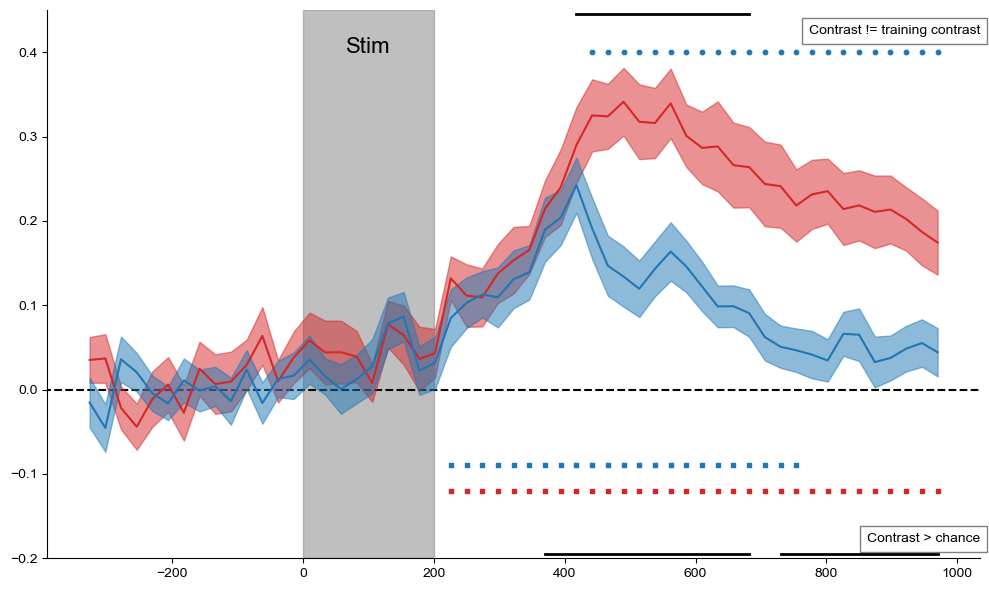

In [44]:
generalize = True
ylim = (-0.2, 0.45)

# Attention, no placeholders
AN_conds = conditions.index("A2N"), conditions.index("A4N")
AN_contrast = preds_per_sub[:, :, AN_conds[1]] - preds_per_sub[:, :, AN_conds[0]]

# Attention, placeholders
AP_conds = conditions.index("A2P"), conditions.index("A4P")
AP_contrast = preds_per_sub[:, :, AP_conds[1]] - preds_per_sub[:, :, AP_conds[0]]

A_contrast = (AP_contrast + AN_contrast) / 2

# Memory, no placeholders
MN_conds = conditions.index("M2N"), conditions.index("M4N")
MN_contrast = preds_per_sub[:, :, MN_conds[1]] - preds_per_sub[:, :, MN_conds[0]]

# Memory, placeholders
MP_conds = conditions.index("M2P"), conditions.index("M4P")
MP_contrast = preds_per_sub[:, :, MP_conds[1]] - preds_per_sub[:, :, MP_conds[0]]

M_contrast = (MP_contrast + MN_contrast) / 2

color_palette = {
    "WM_2vs4": "tab:red",
    "Attn_2vs4": "tab:blue",
}

fig, ax = plt.subplots(1, 1, figsize=(10, 6))

if (RUN_DESCRIPTION == "M2PvsM4P") or (RUN_DESCRIPTION == "M2NvsM4N"):
    cond_scores = [M_contrast, A_contrast]
    labels = ["WM_2vs4", "Attn_2vs4"]
elif (RUN_DESCRIPTION == "A2PvsA4P") or (RUN_DESCRIPTION == "A2NvsA4N"):
    cond_scores = [A_contrast, M_contrast]
    labels = ["Attn_2vs4", "WM_2vs4"]

if not generalize:
    cond_scores = cond_scores[:1]

for i, curr_scores in enumerate(cond_scores):

    mean, upper, lower = interp.get_plot_line(curr_scores)
    ax.plot(times, mean, color_palette[labels[i]], label=labels[i])
    ax.fill_between(times, upper, lower, color=color_palette[labels[i]], alpha=0.5)

    _, clusters, clusters_pv, _ = permutation_cluster_1samp_test(
        curr_scores, n_permutations=5000, tail=1
    )  # NOTE: checking above chance
    for c, p_val in zip(clusters, clusters_pv):
        if p_val < 0.05:
            plt.scatter(
                times[c],
                np.ones(len(times[c])) * (ylim[0] + 0.05 + (i + 1) * 0.03),
                marker="s",
                s=10,
                c=color_palette[labels[i]],
            )

    # now compare the contrast to the training contrast
    if RUN_DESCRIPTION == "M2PvsM4P":
        train_contrast = M_contrast
    elif RUN_DESCRIPTION == "M2NvsM4N":
        train_contrast = M_contrast
    elif RUN_DESCRIPTION == "A2PvsA4P":
        train_contrast = A_contrast
    elif RUN_DESCRIPTION == "A2NvsA4N":
        train_contrast = A_contrast
    diff_contrast = curr_scores - train_contrast
    _, clusters, clusters_pv, _ = permutation_cluster_1samp_test(
        diff_contrast, n_permutations=5000, tail=0
    )  # NOTE: two-tailed here
    for c, p_val in zip(clusters, clusters_pv):
        if p_val < 0.05:
            plt.scatter(
                times[c],
                np.ones(len(times[c])) * (ylim[1] - 0.05),
                marker="o",
                s=10,
                c=color_palette[labels[i]],
            )

plt.legend(loc="lower left")

plt.axhline(
    0, color="black", linestyle="--", alpha=1, zorder=-1, xmin=times.min(), xmax=times.max()
)  # plot theoretical chance level

ax.set_ylim(ylim)
_ = interp.plot_trial_phases(ax, interp.trial_phases, ylim=ylim)
sns.despine()
plt.tight_layout()

ax.text(
    1,
    0.025,
    "Contrast > chance",
    verticalalignment="bottom",
    horizontalalignment="right",
    transform=ax.transAxes,
    fontsize=10,
    bbox={"facecolor": "white", "alpha": 0.5, "pad": 5},
)
ax.text(
    1,
    0.95,
    "Contrast != training contrast",
    verticalalignment="bottom",
    horizontalalignment="right",
    transform=ax.transAxes,
    fontsize=10,
    bbox={"facecolor": "white", "alpha": 0.5, "pad": 5},
)

# for each cluster, plot a black line above the x-axis spanning the time points in the cluster, to visually indicate the significant clusters
for c_info in all_clusters_info:
    c = c_info["time_idxs"]
    plt.plot(times[c], np.ones(len(c)) * (ylim[0] + 0.005), color="black", linewidth=2)

# for each difference cluster, plot a black line below the top of the y-axis spanning the time points in the cluster, to visually indicate the significant clusters
for c_info in all_diff_clusters_info:
    c = c_info["time_idxs"]
    plt.plot(times[c], np.ones(len(c)) * (ylim[1] - 0.005), color="black", linewidth=2)


ax.get_legend().remove()


plt.savefig(
    f"figures/decoding_timecourse_desc-{RUN_DESCRIPTION}_contrasts{f'_noGen' if not generalize else ''}_haufeClustersMarked.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)

plt.savefig(
    f"figures/decoding_timecourse_desc-{RUN_DESCRIPTION}_contrasts{f'_noGen' if not generalize else ''}_haufeClustersMarked.svg",
    bbox_inches="tight",
    transparent=True,
)
plt.show()
plt.close()

In [45]:
from mne.stats import spatio_temporal_cluster_1samp_test

haufe_task_diff_reordered = np.moveaxis(haufe_task_diff, 2, 1)

t_obs, clusters, cluster_p_values, _ = spatio_temporal_cluster_1samp_test(
    haufe_task_diff_reordered, n_permutations=10000, adjacency=adjacency, tail=0
)

Significant spatio-temporal cluster found with p-value 0.0066


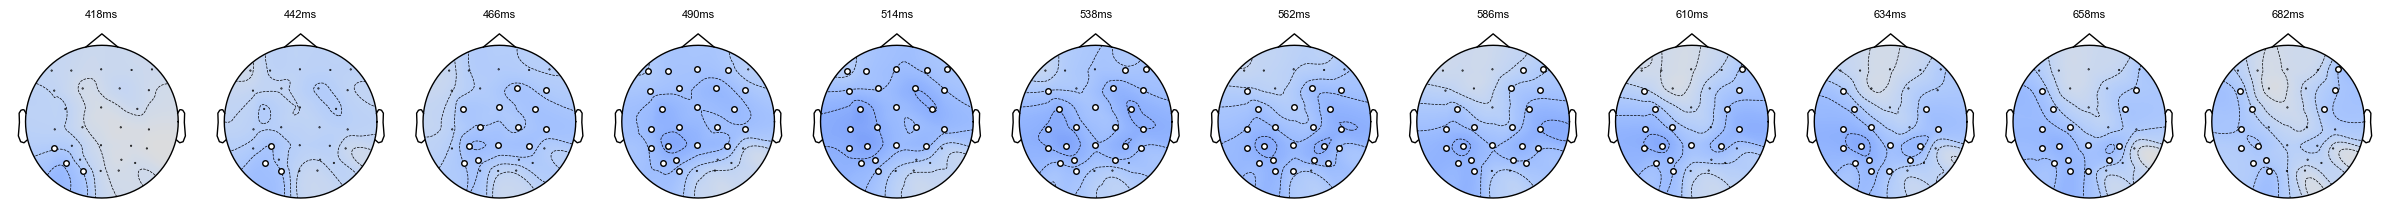

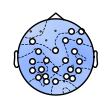

In [46]:
for c, p_val in zip(clusters, cluster_p_values):
    if p_val < 0.05:
        print(f"Significant spatio-temporal cluster found with p-value {p_val:.4f}")
        time_idxs, chan_idxs = c
        curr_mask[chan_idxs] = True
        curr_times = np.unique(time_idxs)
        fig, axes = plt.subplots(1, len(curr_times), figsize=(2 * len(curr_times), 4))

        curr_mask[chan_idxs] = True
        for it, t in enumerate(curr_times):
            curr_chans = chan_idxs[time_idxs == t]
            curr_mask = np.zeros(28, dtype=bool)
            curr_mask[curr_chans] = True

            im, _ = mne.viz.plot_topomap(
                haufe_task_diff_reordered[:, t, :].mean(0),
                info,
                axes=axes[it],
                show=False,
                contours=4,
                vlim=(-0.3, 0.3),
                cmap="coolwarm",
                mask=curr_mask,
                mask_params=dict(marker="o", markerfacecolor="w", markersize=4),
            )
            axes[it].set_title(f"{times[t]}ms", fontsize=8)
        # plt.suptitle(f"{times[curr_times[0]]} - {times[curr_times[-1]]} ms, p={p_val:.4f}", fontsize=12)
        plt.tight_layout()
        plt.savefig(
            f"figures/decoding_desc_HaufeTopomap_taskDiff_cluster_{times[curr_times[0]]}_{times[curr_times[-1]]}ms.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()
        plt.close()
        # get the median time of the cluster. If there are an even number of time points, take the average of the two middle time points
        median_time = np.median(curr_times)
        if len(curr_times) % 2 == 0:
            median_times = np.array([median_time - 0.5, median_time + 0.5])
        else:
            median_times = np.array([median_time])
        # plot the topomap that is the average of the mean importances across the median time points of the cluster
        median_diff = haufe_task_diff_reordered[:, median_times.astype(int), :].mean(1).mean(0)
        median_chans = chan_idxs[np.isin(time_idxs, median_times)]
        median_mask = np.zeros(28, dtype=bool)
        median_mask[median_chans] = True
        im, _ = mne.viz.plot_topomap(
            median_diff,
            info,
            show=False,
            contours=4,
            vlim=(-0.3, 0.3),
            cmap="coolwarm",
            mask=median_mask,
            mask_params=dict(marker="o", markerfacecolor="w", markersize=4),
        )
        plt.savefig(
            f"figures/decoding_desc_HaufeTopomap_taskDiff_clusterMEDIAN_{times[int(median_times[0])]}_{times[int(median_times[-1])]}ms.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()
        plt.close()

# Do placeholders do anything?

In [47]:
attention_pivot_df = (
    combined_df.query("training_conditions == 'Attention'")
    .pivot_table(index=["subject"], columns=["setsize", "placeholder", "task"], values="distance")
    .reset_index()
)
# collapse the columns into 1 level with combined info, for easier plotting
attention_pivot_df.columns = ["subject"] + [
    f"SS{col[0]}_PH{col[1]}_T{col[2]}" for col in attention_pivot_df.columns[1:]
]
attention_pivot_df.to_csv("attention_pivot_df.csv", index=False)
attention_pivot_df

,subject,SS2_PHFalse_TA,SS2_PHFalse_TM,SS2_PHTrue_TA,SS2_PHTrue_TM,SS4_PHFalse_TA,SS4_PHFalse_TM,SS4_PHTrue_TA,SS4_PHTrue_TM,SS6_PHFalse_TA,SS6_PHFalse_TM,SS6_PHTrue_TA,SS6_PHTrue_TM,SS8_PHFalse_TA,SS8_PHFalse_TM,SS8_PHTrue_TA,SS8_PHTrue_TM
0,0,-0.379399,-0.253983,-0.005464,-0.155847,0.030138,-0.261242,0.008541,-0.117162,0.004440,0.107217,0.166782,0.152779,0.091191,0.071907,-0.107721,-0.084284
1,1,-0.432410,-0.077193,-0.099578,-0.067435,-0.072513,0.057118,0.105619,0.011592,-0.201553,0.038593,-0.190910,0.041121,-0.257546,-0.047859,0.000998,0.077288
2,2,-0.137808,-0.443717,-0.103487,0.129565,-0.043718,-0.128487,0.140699,0.011102,0.021556,0.052743,-0.039748,0.058064,-0.012605,0.031490,-0.072452,-0.067914
3,3,-0.090796,-0.108955,0.153596,-0.321856,-0.018373,-0.163828,-0.114091,-0.150057,0.062382,-0.138742,0.110299,-0.107137,0.152889,-0.191329,0.077921,-0.047772
4,4,-0.061406,-0.200045,-0.041232,-0.144165,-0.029142,-0.271174,0.011031,0.059389,-0.112104,-0.143880,-0.140073,-0.044279,0.210990,0.057438,-0.123356,0.032286
5,5,-0.094660,-0.028956,0.027607,-0.101149,-0.051481,0.071157,-0.031627,0.133830,0.049927,0.123058,0.104548,-0.006576,0.137997,0.145645,0.050975,0.292566
6,6,-0.309213,-0.437273,-0.093354,-0.141010,-0.239298,-0.129012,0.119252,-0.122498,-0.004717,-0.308734,-0.038967,-0.107345,-0.109839,0.103475,0.020113,-0.144236
7,7,-0.080984,-0.134898,-0.073646,-0.127717,0.070340,0.128261,0.086251,0.214731,0.256903,0.454823,0.366672,0.427695,0.269099,0.257651,0.397799,0.298989
8,8,-0.521704,-0.241064,-0.000239,-0.357548,-0.177038,-0.201088,0.023706,-0.075518,-0.009537,-0.105844,-0.008791,0.085755,0.049116,-0.018642,0.138871,-0.085906
9,9,-0.109049,-0.058120,-0.005222,-0.103539,0.069473,-0.246189,0.013042,-0.114524,-0.002730,-0.107591,0.243488,-0.105646,0.032932,-0.082134,0.069163,-0.081017


In [48]:
wm_pivot_df = (
    combined_df.query("training_conditions == 'Working Memory'")
    .pivot_table(index=["subject"], columns=["setsize", "placeholder", "task"], values="distance")
    .reset_index()
)
# collapse the columns into 1 level with combined info, for easier plotting
wm_pivot_df.columns = ["subject"] + [f"SS{col[0]}_PH{col[1]}_T{col[2]}" for col in wm_pivot_df.columns[1:]]
wm_pivot_df.to_csv("wm_pivot_df.csv", index=False)
wm_pivot_df

,subject,SS2_PHFalse_TA,SS2_PHFalse_TM,SS2_PHTrue_TA,SS2_PHTrue_TM,SS4_PHFalse_TA,SS4_PHFalse_TM,SS4_PHTrue_TA,SS4_PHTrue_TM,SS6_PHFalse_TA,SS6_PHFalse_TM,SS6_PHTrue_TA,SS6_PHTrue_TM,SS8_PHFalse_TA,SS8_PHFalse_TM,SS8_PHTrue_TA,SS8_PHTrue_TM
0,0,0.021805,0.089638,0.021426,-0.126088,0.080750,0.016694,0.093235,0.140398,0.029710,0.040227,0.100595,0.272298,0.212280,0.052501,0.174468,0.135776
1,1,-0.223420,-0.180434,0.383415,-0.264336,0.091103,0.096619,0.467887,0.308018,0.085041,0.196440,0.158638,0.024604,0.572152,0.348960,0.185328,0.239404
2,2,0.241957,-0.094985,0.222452,-0.259294,0.121317,0.149737,0.063224,0.274383,0.205451,0.116386,0.127354,0.274339,0.196636,0.406336,0.147148,0.248270
3,3,0.010281,0.253002,-0.063814,-0.208466,0.072781,0.163937,-0.004696,0.211300,-0.046609,0.216112,0.118170,0.179461,0.062985,0.156726,-0.001504,0.216174
4,4,0.246850,-0.042822,0.190362,-0.219417,0.401085,0.201589,0.306366,0.179338,0.266991,0.392975,0.286865,0.152724,0.168644,0.133578,0.460196,0.138485
5,5,0.101012,-0.113453,-0.046690,-0.037458,0.020507,0.230188,0.076062,0.050560,0.301443,0.071147,0.106509,0.282297,0.019263,0.260308,0.157341,0.125012
6,6,0.004039,0.044761,0.206046,-0.183447,0.229327,0.168295,0.223444,0.191410,0.153734,0.394445,0.308535,0.519069,0.328537,0.343935,0.259478,0.272985
7,7,-0.035077,-0.149253,-0.034189,-0.252022,0.341911,0.508138,0.257803,0.192618,0.445662,0.493046,0.603329,0.526979,0.403199,0.369225,0.574506,0.269250
8,8,-0.075699,-0.318734,0.013330,-0.334031,0.091967,0.255540,0.270437,0.323458,0.232489,0.463438,0.265298,0.484406,0.252860,0.397768,0.243932,0.444195
9,9,0.043509,-0.351948,0.118963,-0.080999,0.073006,0.022693,0.161521,0.090248,0.074741,0.158135,0.144805,0.126452,0.084868,-0.049935,0.271922,0.093848


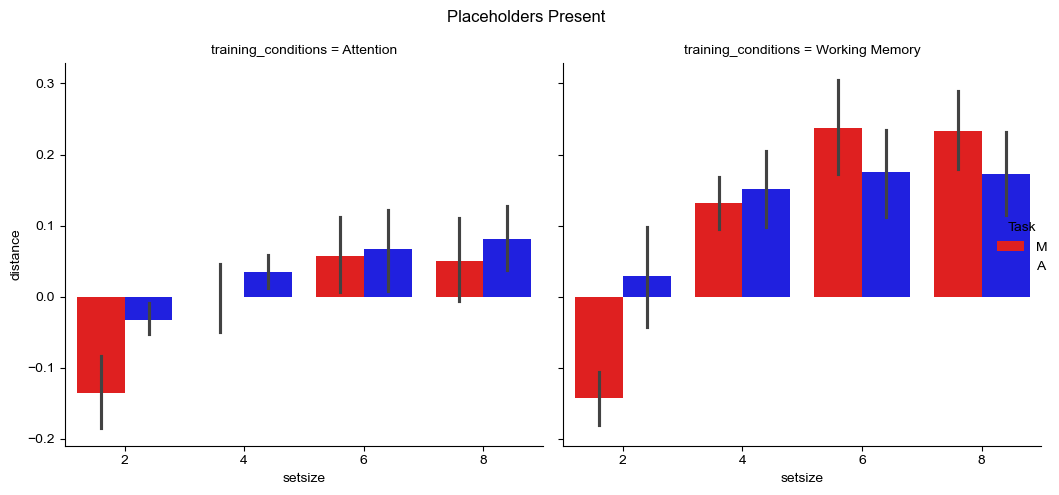

In [49]:
g = sns.FacetGrid(
    combined_df.query("placeholder == True"),
    col="training_conditions",
    height=5,
    aspect=1,
)
g.map(
    sns.barplot,
    "setsize",
    "distance",
    "task",
    palette={"A": "blue", "M": "red"},
    order=["2", "4", "6", "8"],
    hue_order=["M", "A"],
)
_ = g.add_legend(title="Task")
_ = plt.suptitle("Placeholders Present")
plt.tight_layout()

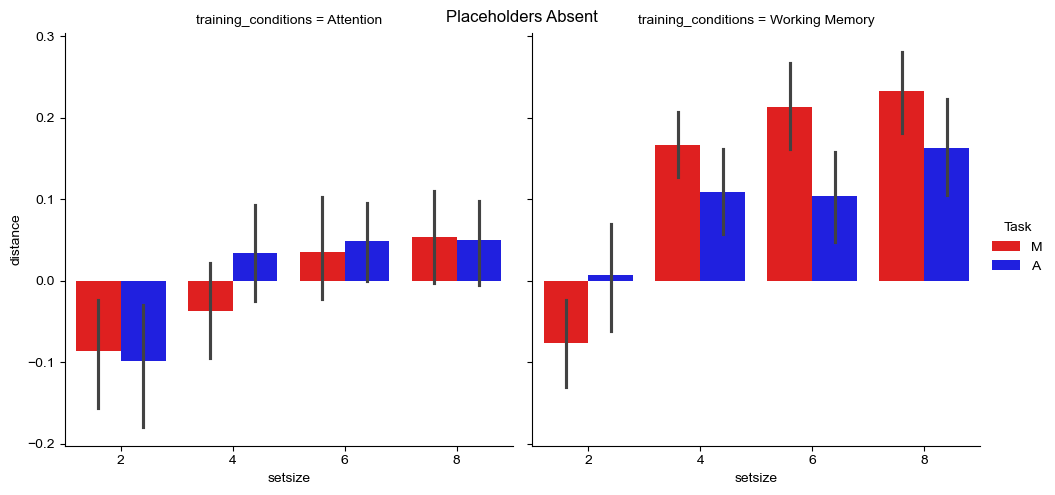

In [50]:
g = sns.FacetGrid(
    combined_df.query("placeholder == False"),
    col="training_conditions",
    height=5,
    aspect=1,
)
g.map(
    sns.barplot,
    "setsize",
    "distance",
    "task",
    palette={"A": "blue", "M": "red"},
    order=["2", "4", "6", "8"],
    hue_order=["M", "A"],
)
_ = g.add_legend(title="Task")
_ = plt.suptitle("Placeholders Absent")

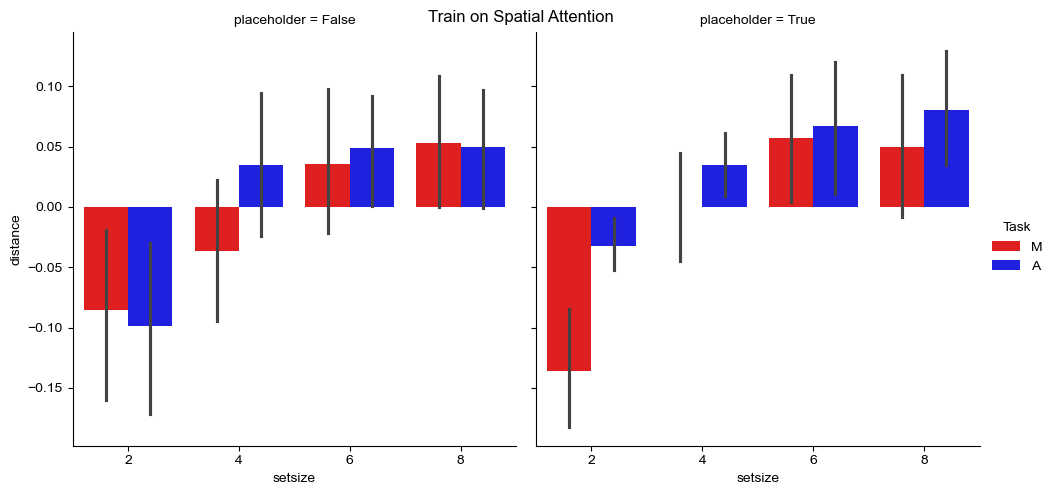

In [51]:
g = sns.FacetGrid(
    combined_df.query("training_conditions == 'Attention'"),
    col="placeholder",
    height=5,
    aspect=1,
)
g.map(
    sns.barplot,
    "setsize",
    "distance",
    "task",
    palette={"A": "blue", "M": "red"},
    order=["2", "4", "6", "8"],
    hue_order=["M", "A"],
)
_ = g.add_legend(title="Task")
_ = plt.suptitle("Train on Spatial Attention")

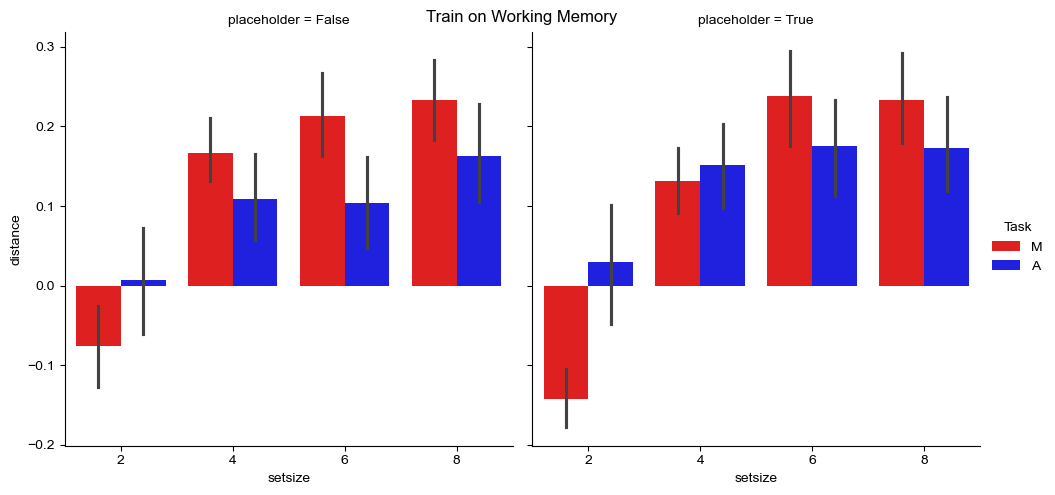

In [52]:
g = sns.FacetGrid(
    combined_df.query("training_conditions == 'Working Memory'"),
    col="placeholder",
    height=5,
    aspect=1,
)
g.map(
    sns.barplot,
    "setsize",
    "distance",
    "task",
    palette={"A": "blue", "M": "red"},
    order=["2", "4", "6", "8"],
    hue_order=["M", "A"],
)
_ = g.add_legend(title="Task")
_ = plt.suptitle("Train on Working Memory")

# Collapsing across placeholder conditions, how do tasks differ by training conds?

In [53]:
combined_df = combined_df.groupby(["subject", "training_conditions", "setsize", "task"]).distance.mean().reset_index()
combined_df

,subject,training_conditions,setsize,task,distance
0,0,Attention,2,A,-0.192432
1,0,Attention,2,M,-0.204915
2,0,Attention,4,A,0.019340
3,0,Attention,4,M,-0.189202
4,0,Attention,6,A,0.085611
...,...,...,...,...,...
411,25,Working Memory,4,M,0.082889
412,25,Working Memory,6,A,-0.015644
413,25,Working Memory,6,M,0.109819
414,25,Working Memory,8,A,0.048628


In [54]:
attention_pivot_df = (
    combined_df.query("training_conditions == 'Attention'")
    .pivot_table(index=["subject"], columns=["setsize", "task"], values="distance")
    .reset_index()
)
# collapse the columns into 1 level with combined info, for easier plotting
attention_pivot_df.columns = ["subject"] + [f"SS{col[0]}_T{col[1]}" for col in attention_pivot_df.columns[1:]]
attention_pivot_df.to_csv("attention_pivot_df_NOPH.csv", index=False)
attention_pivot_df

,subject,SS2_TA,SS2_TM,SS4_TA,SS4_TM,SS6_TA,SS6_TM,SS8_TA,SS8_TM
0,0,-0.192432,-0.204915,0.019340,-0.189202,0.085611,0.129998,-0.008265,-0.006189
1,1,-0.265994,-0.072314,0.016553,0.034355,-0.196231,0.039857,-0.128274,0.014714
2,2,-0.120648,-0.157076,0.048490,-0.058693,-0.009096,0.055403,-0.042528,-0.018212
3,3,0.031400,-0.215405,-0.066232,-0.156942,0.086341,-0.122939,0.115405,-0.119550
4,4,-0.051319,-0.172105,-0.009056,-0.105892,-0.126089,-0.094080,0.043817,0.044862
5,5,-0.033527,-0.065052,-0.041554,0.102493,0.077237,0.058241,0.094486,0.219105
6,6,-0.201284,-0.289141,-0.060023,-0.125755,-0.021842,-0.208040,-0.044863,-0.020381
7,7,-0.077315,-0.131308,0.078296,0.171496,0.311788,0.441259,0.333449,0.278320
8,8,-0.260972,-0.299306,-0.076666,-0.138303,-0.009164,-0.010045,0.093993,-0.052274
9,9,-0.057136,-0.080829,0.041257,-0.180357,0.120379,-0.106618,0.051048,-0.081575


In [55]:
working_memory_pivot_df = (
    combined_df.query("training_conditions == 'Working Memory'")
    .pivot_table(index=["subject"], columns=["setsize", "task"], values="distance")
    .reset_index()
)
# collapse the columns into 1 level with combined info, for easier plotting
working_memory_pivot_df.columns = ["subject"] + [f"SS{col[0]}_T{col[1]}" for col in working_memory_pivot_df.columns[1:]]
working_memory_pivot_df.to_csv("working_memory_pivot_df_NOPH.csv", index=False)
working_memory_pivot_df

,subject,SS2_TA,SS2_TM,SS4_TA,SS4_TM,SS6_TA,SS6_TM,SS8_TA,SS8_TM
0,0,0.021616,-0.018225,0.086993,0.078546,0.065153,0.156263,0.193374,0.094138
1,1,0.079997,-0.222385,0.279495,0.202319,0.121839,0.110522,0.378740,0.294182
2,2,0.232205,-0.177140,0.092271,0.212060,0.166402,0.195362,0.171892,0.327303
3,3,-0.026767,0.022268,0.034042,0.187619,0.035781,0.197787,0.030740,0.186450
4,4,0.218606,-0.131120,0.353726,0.190463,0.276928,0.272850,0.314420,0.136032
5,5,0.027161,-0.075456,0.048284,0.140374,0.203976,0.176722,0.088302,0.192660
6,6,0.105043,-0.069343,0.226385,0.179852,0.231134,0.456757,0.294008,0.308460
7,7,-0.034633,-0.200638,0.299857,0.350378,0.524496,0.510013,0.488852,0.319237
8,8,-0.031184,-0.326383,0.181202,0.289499,0.248893,0.473922,0.248396,0.420981
9,9,0.081236,-0.216474,0.117264,0.056471,0.109773,0.142293,0.178395,0.021956


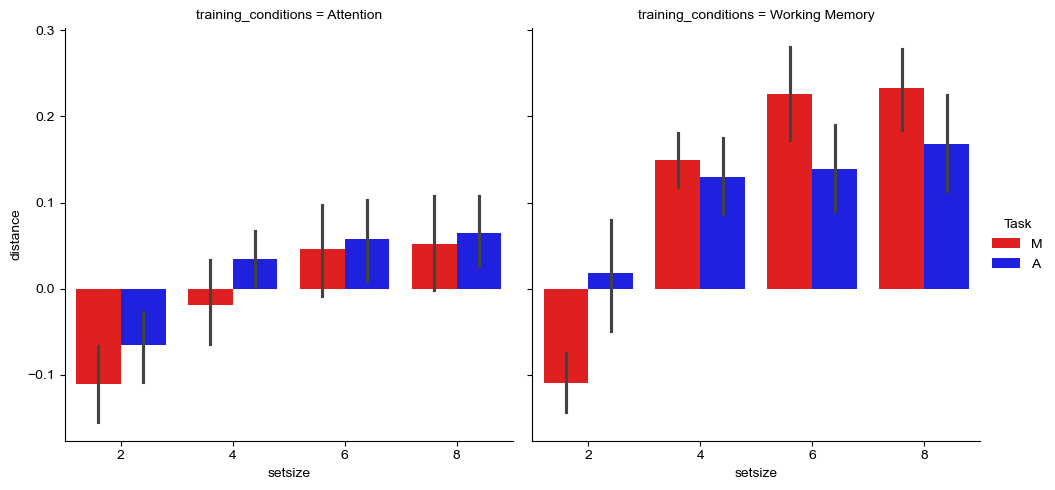

In [56]:
g = sns.FacetGrid(
    combined_df,
    col="training_conditions",
    height=5,
    aspect=1,
)
g.map(
    sns.barplot,
    "setsize",
    "distance",
    "task",
    palette={"A": "blue", "M": "red"},
    order=["2", "4", "6", "8"],
    hue_order=["M", "A"],
)
_ = g.add_legend(title="Task")
plt.savefig("figures/barplot_comparing_models.png", dpi=300, bbox_inches="tight", transparent=True)

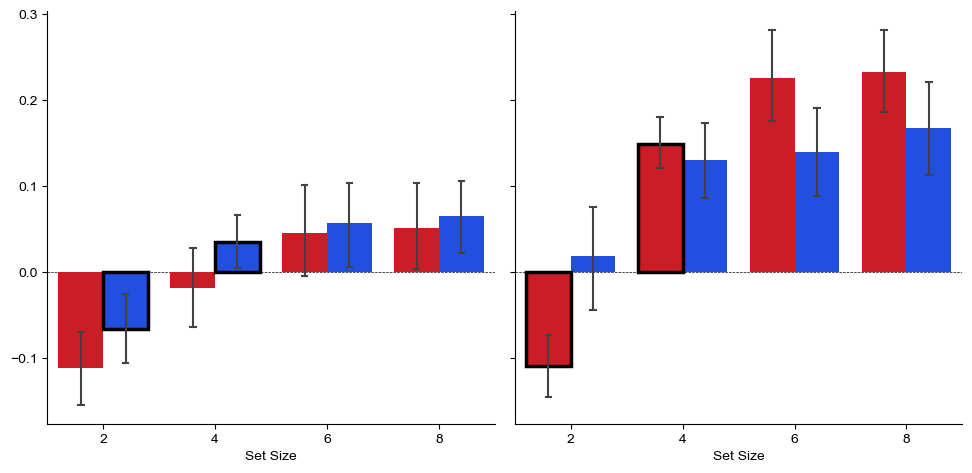

In [59]:
def barplot_with_aligned_outlines(data, x, y, hue, **kwargs):
    order = kwargs.get("order", ["0", "1", "2", "3", "4", "6", "8"])
    hue_order = kwargs.get("hue_order", ["M", "A"])

    ax = sns.barplot(
        data=data,
        x=x,
        y=y,
        hue=hue,
        **kwargs,
    )

    training_condition = data["training_conditions"].iloc[0]
    aligned_task = "A" if training_condition == "Attention" else "M"

    n_hues = len(hue_order)
    bar_width = 0.8 / n_hues

    # Keep all bars below the highlighted outlines.
    for patch in ax.patches:
        patch.set_zorder(1)

    # Highlight the aligned training-condition bars.
    for setsize in ["2", "4"]:
        x_idx = order.index(setsize)
        hue_idx = hue_order.index(aligned_task)
        expected_center = x_idx + (hue_idx - (n_hues - 1) / 2) * bar_width

        matching_bars = [
            patch for patch in ax.patches if abs(patch.get_x() + patch.get_width() / 2 - expected_center) < 1e-6
        ]

        for patch in matching_bars:
            patch.set_edgecolor("black")
            patch.set_linewidth(2.5)
            patch.set_zorder(10)

    # Error bars are stored as Line2D objects and, depending on the
    # seaborn/matplotlib version, LineCollections.
    for line in ax.lines:
        line.set_zorder(20)

    # for collection in ax.collections:
    # collection.set_zorder(20)

    return ax


g = sns.FacetGrid(
    combined_df,
    col="training_conditions",
    height=5,
    aspect=1,
)
g.map_dataframe(
    barplot_with_aligned_outlines,
    x="setsize",
    y="distance",
    hue="task",
    palette={"A": sns.color_palette("bright")[0], "M": sns.color_palette("bright")[3]},
    order=["2", "4", "6", "8"],
    hue_order=["M", "A"],
    errorbar="ci",
    capsize=0.1,
    err_kws={"linewidth": 1.5},
)

# g.add_legend(title="Task")
# drop the y label and title
g.set_axis_labels("Set Size", "")
g.set_titles("")
# add a thin line at y=0
for ax in g.axes.flat:
    ax.axhline(y=0, color="black", linewidth=0.5, linestyle="--", zorder=0)


plt.savefig("figures/barplot_comparing_models_trainingOutlined.png", dpi=300, bbox_inches="tight", transparent=True)

plt.show()
plt.close()

In [ ]:
pg.rm_anova(
    data=combined_df.query("training_conditions == 'Attention'"),
    dv="distance",
    within=["setsize", "task"],
    subject="subject",
)

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,setsize,0.713441,3,75,0.237814,24.977862,2.613922e-11,1.199592e-08,0.200473,0.710066
1,task,0.050121,1,25,0.050121,3.368714,7.837019e-02,7.837019e-02,0.017310,1.000000
2,setsize * task,0.017991,3,75,0.005997,1.394254,2.511628e-01,2.526574e-01,0.006283,0.941317


In [ ]:
pg.rm_anova(
    data=combined_df.query("training_conditions == 'Working Memory'"),
    dv="distance",
    within=["setsize", "task"],
    subject="subject",
)

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,setsize,1.984766,3,75,0.661589,58.962273,1.093921e-19,1.867651e-12,0.372740,0.585142
1,task,0.005903,1,25,0.005903,0.189928,6.667164e-01,6.667164e-01,0.001764,1.000000
2,setsize * task,0.361968,3,75,0.120656,23.718152,6.724263e-11,9.606275e-09,0.097777,0.754467


## Repeated measures anovas for a given task, with a factor for the training conditions

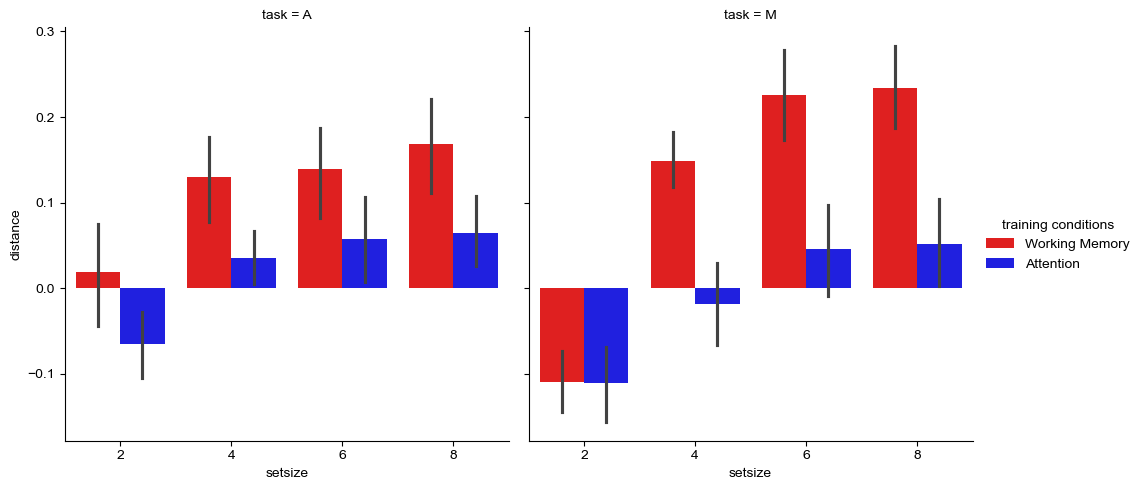

In [ ]:
g = sns.FacetGrid(
    combined_df,
    col="task",
    height=5,
    aspect=1,
)
g.map(
    sns.barplot,
    "setsize",
    "distance",
    "training_conditions",
    palette={"Attention": "blue", "Working Memory": "red"},
    order=["2", "4", "6", "8"],
    hue_order=["Working Memory", "Attention"],
)
_ = g.add_legend(title="training conditions")

In [ ]:
pg.rm_anova(
    data=combined_df.query("task == 'A'"), dv="distance", within=["setsize", "training_conditions"], subject="subject"
)

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,setsize,0.617990,3,75,0.205997,25.378891,1.944330e-11,5.167397e-08,0.161135,0.632349
1,training_conditions,0.430451,1,25,0.430451,7.347344,1.196095e-02,1.196095e-02,0.118007,1.000000
2,setsize * training_conditions,0.003883,3,75,0.001294,0.415620,7.422818e-01,7.178631e-01,0.001206,0.882679


In [ ]:
pg.rm_anova(
    data=combined_df.query("task == 'M'"), dv="distance", within=["setsize", "training_conditions"], subject="subject"
)

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,setsize,2.157768,3,75,0.719256,61.785672,3.185731e-20,3.398521e-14,0.420953,0.664222
1,training_conditions,0.915458,1,25,0.915458,32.874531,5.663376e-06,5.663376e-06,0.235724,1.000000
2,setsize * training_conditions,0.298525,3,75,0.099508,13.711361,3.214781e-07,4.086377e-06,0.091385,0.788678


# Repeating but with Eyes

In [ ]:
attn_interp = mvEEG.Interpreter(
    data_dir=ROOT,
    experiment_name=EXPERIMENT_NAME,
    descriptions=["A2PvsA4P"],
    labels=[0, 1],
    trial_phases={"Stim": (0, 200)},
    key_set=["times", "predsEYES"],
)
preds_attn, times = attn_interp.dataset.get_data(None, keys=["predsEYES", "times"])
preds_attn_per_sub = preds_attn.mean(2).mean(1)[:, delay_window, :].mean(1)
full_df_attn = pd.DataFrame(preds_attn_per_sub, columns=conditions)
full_df_attn["subject"] = full_df_attn.index.values
melted_df_attn = full_df_attn.melt(id_vars="subject", var_name="condition", value_name="distance")
melted_df_attn.loc[:, "task"] = melted_df_attn.condition.str[0]
melted_df_attn.loc[:, "setsize"] = melted_df_attn.condition.str[1]
melted_df_attn["training_conditions"] = "Attention"
melted_df_attn["placeholder"] = melted_df_attn.condition.str[2] == "P"

del attn_interp

wm_interp = mvEEG.Interpreter(
    data_dir=ROOT,
    experiment_name=EXPERIMENT_NAME,
    descriptions=["M2PvsM4P"],
    labels=[0, 1],
    trial_phases={"Stim": (0, 200)},
    key_set=["predsEYES"],
)
preds_wm = wm_interp.dataset.get_data(None, keys=["predsEYES"])
preds_wm_per_sub = preds_wm.mean(2).mean(1)[:, delay_window, :].mean(1)
full_df_wm = pd.DataFrame(preds_wm_per_sub, columns=conditions)
full_df_wm["subject"] = full_df_wm.index.values
melted_df_wm = full_df_wm.melt(id_vars="subject", var_name="condition", value_name="distance")
melted_df_wm.loc[:, "task"] = melted_df_wm.condition.str[0]
melted_df_wm.loc[:, "setsize"] = melted_df_wm.condition.str[1]
melted_df_wm["training_conditions"] = "Working Memory"
melted_df_wm["placeholder"] = melted_df_wm.condition.str[2] == "P"

combined_df = pd.concat([melted_df_attn, melted_df_wm], axis=0).reset_index(drop=True)

del wm_interp

## Do placeholders do anything?

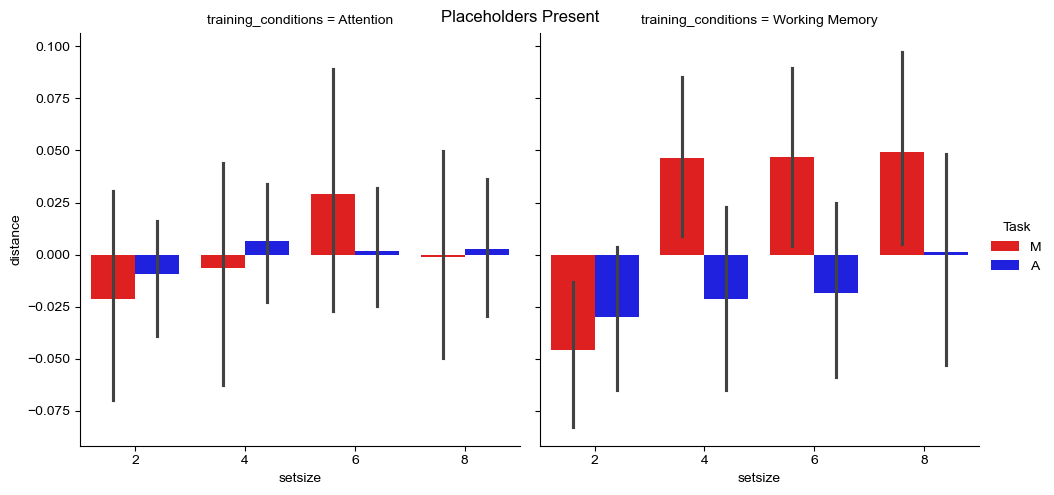

In [ ]:
g = sns.FacetGrid(
    combined_df.query("placeholder == True"),
    col="training_conditions",
    height=5,
    aspect=1,
)
g.map(
    sns.barplot,
    "setsize",
    "distance",
    "task",
    palette={"A": "blue", "M": "red"},
    order=["2", "4", "6", "8"],
    hue_order=["M", "A"],
)
_ = g.add_legend(title="Task")
_ = plt.suptitle("Placeholders Present")

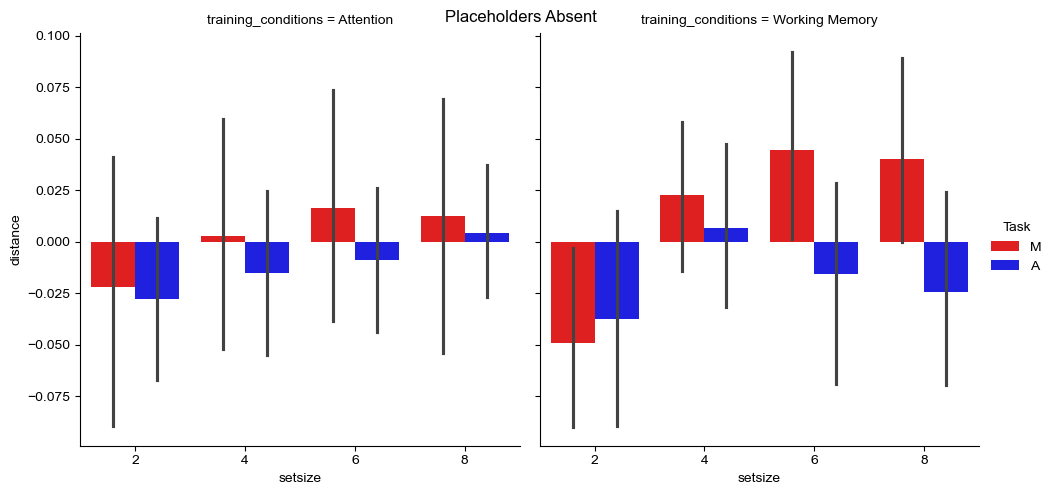

In [ ]:
g = sns.FacetGrid(
    combined_df.query("placeholder == False"),
    col="training_conditions",
    height=5,
    aspect=1,
)
g.map(
    sns.barplot,
    "setsize",
    "distance",
    "task",
    palette={"A": "blue", "M": "red"},
    order=["2", "4", "6", "8"],
    hue_order=["M", "A"],
)
_ = g.add_legend(title="Task")
_ = plt.suptitle("Placeholders Absent")

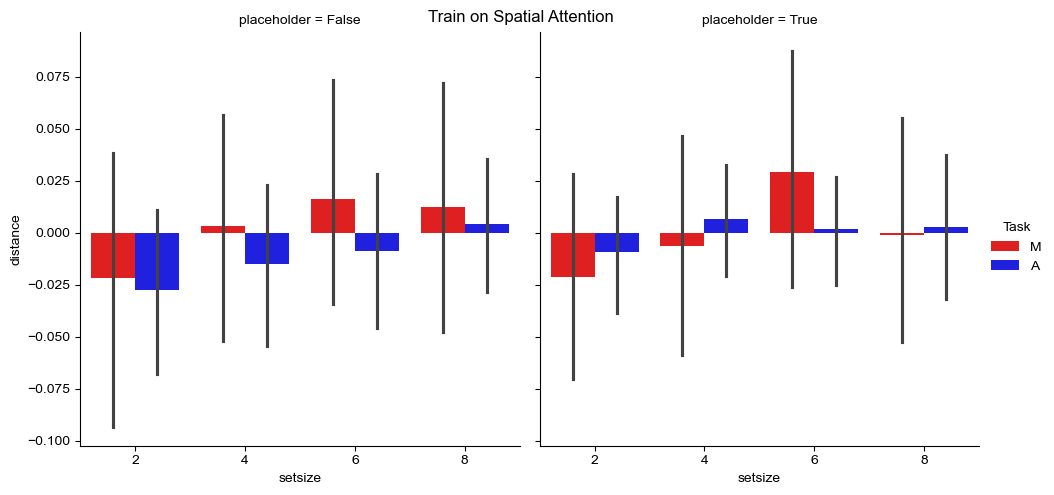

In [ ]:
g = sns.FacetGrid(
    combined_df.query("training_conditions == 'Attention'"),
    col="placeholder",
    height=5,
    aspect=1,
)
g.map(
    sns.barplot,
    "setsize",
    "distance",
    "task",
    palette={"A": "blue", "M": "red"},
    order=["2", "4", "6", "8"],
    hue_order=["M", "A"],
)
_ = g.add_legend(title="Task")
_ = plt.suptitle("Train on Spatial Attention")

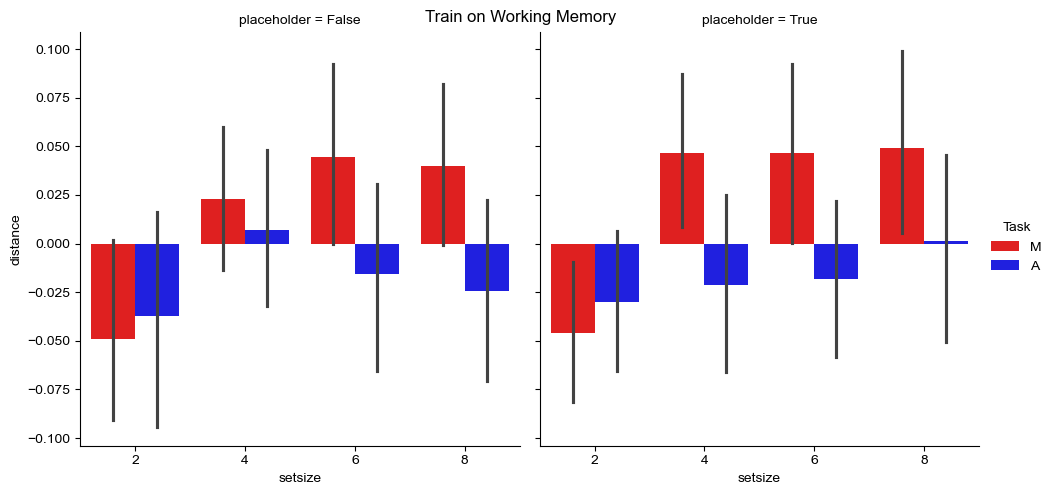

In [ ]:
g = sns.FacetGrid(
    combined_df.query("training_conditions == 'Working Memory'"),
    col="placeholder",
    height=5,
    aspect=1,
)
g.map(
    sns.barplot,
    "setsize",
    "distance",
    "task",
    palette={"A": "blue", "M": "red"},
    order=["2", "4", "6", "8"],
    hue_order=["M", "A"],
)
_ = g.add_legend(title="Task")
_ = plt.suptitle("Train on Working Memory")

In [ ]:
pg.rm_anova(
    data=combined_df,
    dv="distance",
    within=["setsize", "placeholder"],
    subject="subject",
)

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,setsize,0.062247,3,75,0.020749,4.486866,0.005959,0.025054,0.056074,0.521387
1,placeholder,0.001290,1,25,0.001290,0.639618,0.431383,0.431383,0.001230,1.000000
2,setsize * placeholder,0.000214,3,75,0.000071,0.052484,0.984018,0.979763,0.000204,0.930971


# Collapsing across placeholder conditions, how to tasks differ by training conditions?

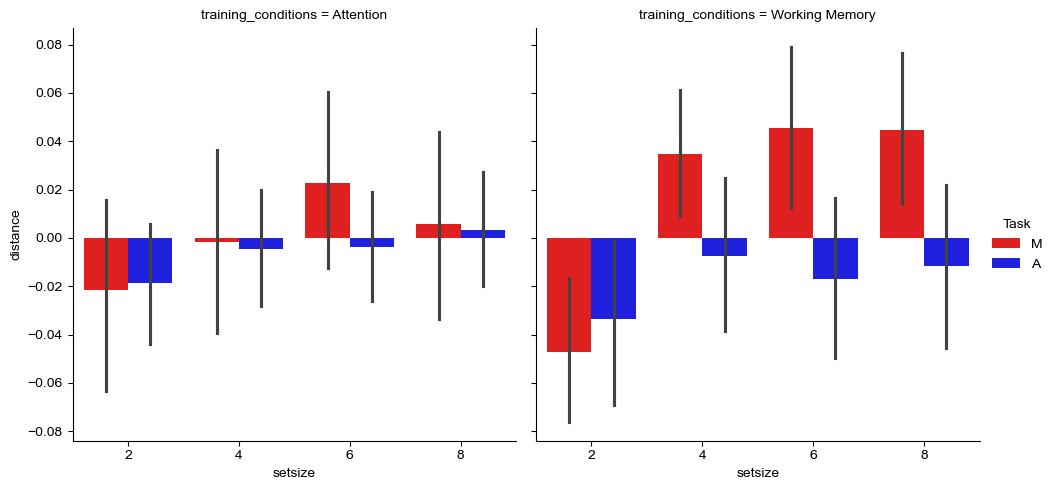

In [ ]:
g = sns.FacetGrid(
    combined_df,
    col="training_conditions",
    height=5,
    aspect=1,
)
g.map(
    sns.barplot,
    "setsize",
    "distance",
    "task",
    palette={"A": "blue", "M": "red"},
    order=["2", "4", "6", "8"],
    hue_order=["M", "A"],
)
_ = g.add_legend(title="Task")

In [ ]:
pg.rm_anova(
    data=combined_df.query("training_conditions == 'Attention'"),
    dv="distance",
    within=["setsize", "task"],
    subject="subject",
)

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,setsize,0.026216,3,75,0.008739,1.679492,0.178613,0.201982,0.010683,0.557337
1,task,0.002598,1,25,0.002598,0.107701,0.745510,0.745510,0.001069,1.000000
2,setsize * task,0.006832,3,75,0.002277,0.926266,0.432367,0.423040,0.002806,0.876649


In [ ]:
pg.rm_anova(
    data=combined_df.query("training_conditions == 'Working Memory'"),
    dv="distance",
    within=["setsize", "task"],
    subject="subject",
)

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,setsize,0.119656,3,75,0.039885,6.258251,0.000754,0.004946,0.053611,0.609996
1,task,0.070304,1,25,0.070304,2.563148,0.121943,0.121943,0.032212,1.000000
2,setsize * task,0.047141,3,75,0.015714,6.002002,0.001011,0.002886,0.021831,0.768877


## Repeated measures anovas for a given task, with a factor for the training conditions

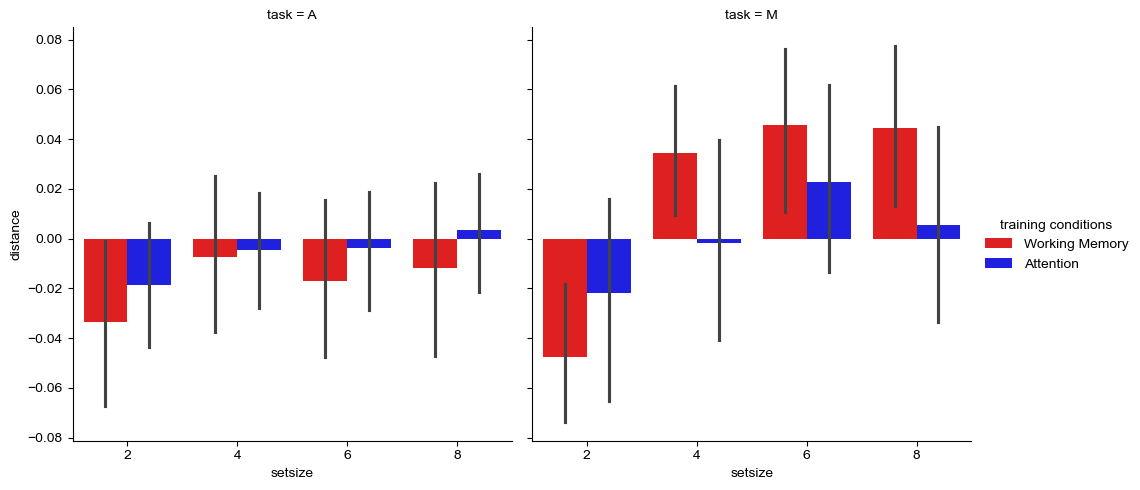

In [ ]:
g = sns.FacetGrid(
    combined_df,
    col="task",
    height=5,
    aspect=1,
)
g.map(
    sns.barplot,
    "setsize",
    "distance",
    "training_conditions",
    palette={"Attention": "blue", "Working Memory": "red"},
    order=["2", "4", "6", "8"],
    hue_order=["Working Memory", "Attention"],
)
_ = g.add_legend(title="training conditions")

In [ ]:
pg.rm_anova(
    data=combined_df.query("task == 'A'"), dv="distance", within=["setsize", "training_conditions"], subject="subject"
)

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,setsize,0.015584,3,75,0.005195,1.127812,0.343324,0.332343,0.008840,0.676214
1,training_conditions,0.006993,1,25,0.006993,0.372956,0.546910,0.546910,0.003986,1.000000
2,setsize * training_conditions,0.001328,3,75,0.000443,0.264320,0.850896,0.805675,0.000760,0.794144


In [ ]:
pg.rm_anova(
    data=combined_df.query("task == 'M'"), dv="distance", within=["setsize", "training_conditions"], subject="subject"
)

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,setsize,0.147669,3,75,0.049223,6.904729,0.000362,0.004681,0.050221,0.534732
1,training_conditions,0.017044,1,25,0.017044,0.475946,0.496619,0.496619,0.006066,1.000000
2,setsize * training_conditions,0.035264,3,75,0.011755,3.624498,0.016781,0.026696,0.012470,0.779148
